Notebook narratif : la théorie et les résultats. Le code réutilisable est dans `var_es/`. Le README présente la synthèse et la comparaison complète des six modèles ; ce notebook détaille la construction des méthodes, section par section.

# Value at Risk (VaR) et Expected Shortfall (ES)

## Introduction

La gestion du risque de marché vise à quantifier les pertes potentielles associées à des positions financières dans un environnement de marché incertain. Parmi les mesures de risque les plus utilisées figurent la **Value at Risk (VaR)** et l’**Expected Shortfall (ES)**.

La Value at Risk est un quantile de la distribution des pertes à un niveau de confiance donné. Elle ne dit cependant rien de l’ampleur des pertes au-delà de ce seuil. L’Expected Shortfall répond à cette limite en mesurant la perte moyenne dans la queue de la distribution.

L’objectif de ce projet est d’implémenter, de comparer et d’évaluer plusieurs méthodes d’estimation de la VaR et de l’ES pour un portefeuille multi-actifs. L’analyse combine modèles paramétriques, méthodes historiques, simulation de Monte-Carlo et backtesting statistique.

L’accent est mis sur les propriétés statistiques de ces mesures de risque, sur leur sensibilité aux hypothèses de modélisation et sur leur performance sur données financières.

## Définitions mathématiques

Soit $L$ la variable aléatoire représentant la perte du portefeuille sur un horizon fixé. Les valeurs positives de $L$ correspondent à des pertes, les valeurs négatives à des gains.

Soit $F_L$ la fonction de répartition de $L$, définie par :

$$
F_L(x)=\mathbb{P}(L\leq x).
$$

Pour un niveau de confiance $\alpha\in(0,1)$, la Value at Risk est le quantile d’ordre $\alpha$ de la distribution des pertes :

$$
\boxed{
\operatorname{VaR}_{\alpha}(L)
=
\inf\{x\in\mathbb{R}:F_L(x)\geq\alpha\}
}
$$

Pour une distribution continue des pertes, c’est le seuil vérifiant :

$$
\mathbb{P}\left(L\leq\operatorname{VaR}_{\alpha}(L)\right)
=\alpha.
$$

L’Expected Shortfall est la moyenne des VaR sur les niveaux de confiance compris entre $\alpha$ et $1$ :

$$
\boxed{
\operatorname{ES}_{\alpha}(L)
=
\frac{1}{1-\alpha}
\int_{\alpha}^{1}\operatorname{VaR}_{u}(L)\,du
}
$$

Pour une distribution continue, l’Expected Shortfall s’écrit aussi comme l’espérance de la perte conditionnellement au dépassement du seuil de VaR :

$$
\operatorname{ES}_{\alpha}(L)
=
\mathbb{E}\left[
L\mid L>\operatorname{VaR}_{\alpha}(L)
\right].
$$

Pour des distributions discrètes ou empiriques, cette espérance conditionnelle peut différer de la définition intégrale, car une masse de probabilité peut se situer exactement au seuil de VaR. La définition intégrale est donc la formulation la plus générale.

L’Expected Shortfall renseigne sur la sévérité des pertes dans la partie la plus défavorable de la distribution, au-delà du seuil de VaR.

## Interprétation

Considérons un portefeuille dont les mesures de risque estimées au niveau de confiance de 99 % sont :

$$
\operatorname{VaR}_{0.99}=2\,000\text{ €}
$$

et

$$
\operatorname{ES}_{0.99}=2\,800\text{ €}.
$$

La VaR indique que la perte du portefeuille devrait dépasser 2 000 € dans environ 1 % des cas, sous l’hypothèse d’une distribution continue des pertes.

L’ES indique que la perte moyenne dans les 1 % de cas les plus défavorables est estimée à 2 800 €.

Ces grandeurs sont des estimations : elles dépendent du modèle, des données et de l’horizon choisi.

Dans tout le projet, les pertes sont exprimées en unités monétaires, et le niveau de confiance $\alpha$ est distingué de la probabilité de queue $1-\alpha$.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt

from var_es.models import (
    gaussian_loss_params,
    var_es_gaussian,
    var_es_monte_carlo,
    var_es_empirical,
    simulate_returns,
)

from var_es.portfolio import covariance_from_vol_corr
from var_es.plots import plot_loss_distribution

# 1. Simulation de Monte-Carlo d’un portefeuille multi-actifs

## 1.1 Description du portefeuille

On considère un portefeuille composé de trois actifs, notés A, B et C.

La valeur initiale du portefeuille est :

$$
V_0 = 100\,000\text{ €}
$$

L’allocation du portefeuille est la suivante :

| Actif | Investissement | Poids dans le portefeuille |
|---|---:|---:|
| A | 50 000 € | 50 % |
| B | 30 000 € | 30 % |
| C | 20 000 € | 20 % |
| **Total** | **100 000 €** | **100 %** |

Le vecteur des poids est donc :

$$
w =
\begin{pmatrix}
0.5\\
0.3\\
0.2
\end{pmatrix}
$$

On suppose que les rendements journaliers des trois actifs suivent une loi gaussienne multivariée :

$$
R \sim \mathcal{N}(\mu,\Sigma)
$$

où :

- $\mu$ est le vecteur des rendements journaliers espérés ;
- $\Sigma$ est la matrice de covariance des rendements.

Pour cette expérience, les paramètres suivants sont supposés :

| Paramètre | Actif A | Actif B | Actif C |
|---|---:|---:|---:|
| Rendement journalier espéré | 0,05 % | 0,03 % | 0,04 % |
| Volatilité journalière | 2,0 % | 1,5 % | 2,5 % |

Le vecteur des rendements espérés est :

$$
\mu =
\begin{pmatrix}
0.0005\\
0.0003\\
0.0004
\end{pmatrix}
$$

Le vecteur des volatilités est :

$$
\sigma =
\begin{pmatrix}
0.02\\
0.015\\
0.025
\end{pmatrix}
$$

La matrice de corrélation est supposée égale à :

$$
\rho =
\begin{pmatrix}
1 & 0.6 & 0.3\\
0.6 & 1 & 0.4\\
0.3 & 0.4 & 1
\end{pmatrix}
$$

La matrice de covariance est construite par :

$$
\Sigma = D\rho D
$$

où $D$ est la matrice diagonale des volatilités des actifs :

$$
D =
\begin{pmatrix}
\sigma_A & 0 & 0\\
0 & \sigma_B & 0\\
0 & 0 & \sigma_C
\end{pmatrix}
$$

Cette construction garantit que la matrice de covariance intègre à la fois les volatilités individuelles et les corrélations deux à deux.

## 1.2 Rendement du portefeuille et distribution des pertes

Le rendement journalier du portefeuille est la somme pondérée des rendements des actifs :

$$
R_p = w^\top R
$$

Sous l’hypothèse gaussienne multivariée, le rendement du portefeuille est lui aussi gaussien :

$$
R_p \sim \mathcal{N}(\mu_p,\sigma_p^2)
$$

où le rendement espéré du portefeuille est :

$$
\mu_p = w^\top\mu
$$

et la variance du portefeuille :

$$
\sigma_p^2 = w^\top\Sigma w.
$$

La valeur du portefeuille à la fin de l’horizon d’un jour est approchée par :

$$
V_1 = V_0(1+R_p)
$$

La perte correspondante est définie par :

$$
L = V_0 - V_1 = -V_0R_p.
$$

La distribution des pertes est donc également gaussienne :

$$
L \sim \mathcal{N}(\mu_L,\sigma_L^2)
$$

avec :

$$
\mu_L=-V_0\mu_p
$$

et :

$$
\sigma_L=V_0\sigma_p.
$$

Ce cadre analytique fournit une référence théorique pour évaluer les estimations Monte-Carlo.

## 1.3 Simulation de Monte-Carlo

La méthode de Monte-Carlo consiste à générer un grand nombre de scénarios de marché possibles à partir de la distribution multivariée supposée.

Pour chaque simulation $i$, on génère un vecteur de rendements des actifs :

$$
R^{(i)} \sim \mathcal{N}(\mu,\Sigma)
$$

La perte correspondante du portefeuille est calculée par :

$$
L_{i}=-V_0w^\top R^{(i)}.
$$

En répétant cette procédure $N$ fois, on obtient l’échantillon de pertes simulées :

$$
\{L_{1},L_{2},\ldots,L_{N}\}.
$$

Dans cette expérience, on utilise :

- $N=100\,000$ simulations de Monte-Carlo ;
- une graine aléatoire fixée, pour la reproductibilité ;
- un horizon de risque d’un jour ;
- des niveaux de confiance de 95 % et 99 %.

### Estimation de la VaR par Monte-Carlo

L’estimateur Monte-Carlo de la VaR au niveau de confiance $\alpha$ est le quantile empirique :

$$
\widehat{VaR}_{\alpha,N}
=
\inf\left\{
x :
\widehat{F}_N(x)\geq\alpha
\right\}
$$

où la fonction de répartition empirique est :

$$
\widehat{F}_N(x)
=
\frac{1}{N}
\sum_{i=1}^{N}
\mathbf{1}_{\{L_i\leq x\}}
$$

L’estimateur de l’Expected Shortfall s’obtient en moyennant les pertes qui dépassent la VaR estimée :

$$
\widehat{ES}_{\alpha,N}
=
\frac{
\sum_{i=1}^{N}
L_i\mathbf{1}_{\{L_i>\widehat{VaR}_{\alpha,N}\}}
}{
\sum_{i=1}^{N}
\mathbf{1}_{\{L_i>\widehat{VaR}_{\alpha,N}\}}
}
$$

Cet estimateur donne une approximation empirique de la perte moyenne dans la queue supérieure de la distribution.

## 1.4 Référence analytique

Un avantage du cadre gaussien est que la VaR et l’Expected Shortfall ont toutes deux des expressions en forme fermée.

Ces valeurs théoriques servent de référence pour évaluer les estimations Monte-Carlo.

Soient $\Phi$ et $\phi$ la fonction de répartition et la densité de la loi normale centrée réduite.

La Value at Risk théorique est :

$$
\operatorname{VaR}_\alpha(L)
=
\mu_L+\sigma_L\Phi^{-1}(\alpha)
$$

L’Expected Shortfall théorique est :

$$
\operatorname{ES}_\alpha(L)
=
\mu_L+
\sigma_L
\frac{\phi(\Phi^{-1}(\alpha))}{1-\alpha}
$$

La comparaison de ces expressions analytiques avec les estimations Monte-Carlo permet d’évaluer la précision de la simulation.

## 1.5 Objectifs et limites

Cette première expérience numérique vise à :

- vérifier la cohérence entre les estimations Monte-Carlo et les mesures de risque gaussiennes théoriques ;
- illustrer la différence entre VaR et Expected Shortfall ;
- comprendre comment les volatilités individuelles et les corrélations influencent le risque du portefeuille ;
- introduire les méthodes numériques utilisées dans la suite du projet.

### Limites du modèle

L’hypothèse gaussienne offre un cadre analytique commode, mais elle ne reproduit pas toujours bien les propriétés statistiques des rendements financiers.

En particulier, les rendements financiers présentent souvent :

- **des queues épaisses** : les observations extrêmes sont plus fréquentes que ne le prévoit une loi gaussienne ;
- **un regroupement de volatilité** : les périodes de forte volatilité se succèdent ;
- **une dépendance non linéaire** : les corrélations seules ne décrivent pas entièrement la dépendance entre actifs.

De plus, le modèle suppose des rendements espérés et une covariance constants sur l’horizon de risque.

Ces limites motivent les modèles plus sophistiqués introduits dans les sections suivantes : simulation historique, lois de Student multivariées et modèles de volatilité dynamique.

In [2]:
# Paramètres du portefeuille
V0 = 100_000

weights = np.array([0.50, 0.30, 0.20])

mu = np.array([0.0005, 0.0003, 0.0004])

vol = np.array([0.020, 0.015, 0.025])

corr = np.array([
    [1.0, 0.6, 0.3],
    [0.6, 1.0, 0.4],
    [0.3, 0.4, 1.0]
])

# Matrice de covariance
cov = covariance_from_vol_corr(vol, corr)

# Simulation de Monte-Carlo
N = 100_000
rng = np.random.default_rng(42)

returns = simulate_returns(mu, cov, N, rng=rng)

# Pertes du portefeuille
losses = -V0 * (returns @ weights)

# Paramètres gaussiens analytiques
mean_loss, std_loss = gaussian_loss_params(mu, cov, weights, V0)

# Estimation des mesures de risque
results = {}

for alpha in (0.95, 0.99):

    # Estimations empiriques à partir des pertes simulées
    var_mc, es_mc = var_es_empirical(losses, alpha)

    # Estimations gaussiennes analytiques
    var_th, es_th = var_es_gaussian(mean_loss, std_loss, alpha)

    results[alpha] = {
        "var_mc": var_mc,
        "es_mc": es_mc,
        "var_th": var_th,
        "es_th": es_th
    }

    print(
        f"{alpha:.0%} | "
        f"Monte-Carlo : VaR = {var_mc:,.2f} €, "
        f"ES = {es_mc:,.2f} € | "
        f"Théorique : VaR = {var_th:,.2f} €, "
        f"ES = {es_th:,.2f} €"
    )


95% | Monte-Carlo : VaR = 2,544.36 €, ES = 3,214.56 € | Théorique : VaR = 2,544.40 €, ES = 3,201.45 €
99% | Monte-Carlo : VaR = 3,637.04 €, ES = 4,188.14 € | Théorique : VaR = 3,615.99 €, ES = 4,148.83 €


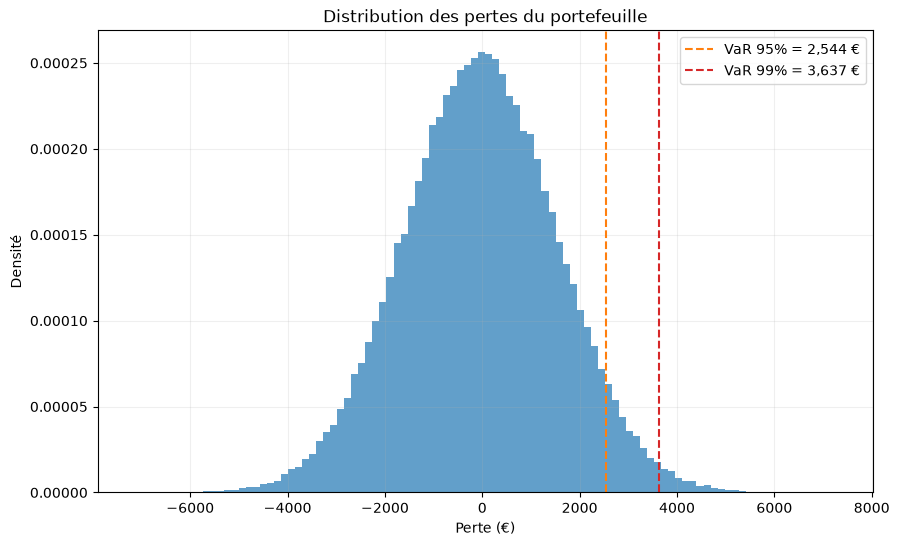

In [3]:
fig = plot_loss_distribution(
    losses,
    title="Distribution des pertes du portefeuille"
)
plt.show()

In [4]:
from IPython.display import display, Markdown

# Extraction des résultats
r95 = results[0.95]
r99 = results[0.99]

# Erreurs relatives par rapport aux valeurs analytiques
var_error_95 = abs(r95["var_mc"] - r95["var_th"]) / abs(r95["var_th"]) * 100
es_error_95 = abs(r95["es_mc"] - r95["es_th"]) / abs(r95["es_th"]) * 100

var_error_99 = abs(r99["var_mc"] - r99["var_th"]) / abs(r99["var_th"]) * 100
es_error_99 = abs(r99["es_mc"] - r99["es_th"]) / abs(r99["es_th"]) * 100

# Génération dynamique de l’interprétation
display(Markdown(f"""
### Interprétation des résultats Monte-Carlo

La simulation de Monte-Carlo repose sur **{N:,} scénarios**
pour un portefeuille de valeur initiale **{V0:,.0f} €**.

#### Estimations des mesures de risque

Au niveau de confiance de 95 % :

- VaR estimée : **{r95['var_mc']:,.2f} €**
- ES estimée : **{r95['es_mc']:,.2f} €**
- VaR théorique : **{r95['var_th']:,.2f} €**
- ES théorique : **{r95['es_th']:,.2f} €**

Au niveau de confiance de 99 % :

- VaR estimée : **{r99['var_mc']:,.2f} €**
- ES estimée : **{r99['es_mc']:,.2f} €**
- VaR théorique : **{r99['var_th']:,.2f} €**
- ES théorique : **{r99['es_th']:,.2f} €**

#### Comparaison avec les résultats analytiques

Au niveau de confiance de 95 %, les erreurs relatives d’estimation sont :

- VaR : **{var_error_95:.3f} %**
- ES : **{es_error_95:.3f} %**

Au niveau de confiance de 99 %, les erreurs relatives d’estimation sont :

- VaR : **{var_error_99:.3f} %**
- ES : **{es_error_99:.3f} %**

#### Interprétation

La VaR estimée augmente quand le niveau de confiance passe de 95 % à 99 %, car des pertes plus extrêmes sont prises en compte.

L’Expected Shortfall est supérieure à la VaR à chaque niveau de confiance, puisqu’elle mesure la perte moyenne au-delà du quantile correspondant.

La comparaison avec la référence gaussienne analytique permet d’évaluer la précision de l’estimation Monte-Carlo. Les écarts entre les deux approches proviennent de la variabilité de la simulation et des effets de taille d’échantillon finie.
"""))


### Interprétation des résultats Monte-Carlo

La simulation de Monte-Carlo repose sur **100,000 scénarios**
pour un portefeuille de valeur initiale **100,000 €**.

#### Estimations des mesures de risque

Au niveau de confiance de 95 % :

- VaR estimée : **2,544.36 €**
- ES estimée : **3,214.56 €**
- VaR théorique : **2,544.40 €**
- ES théorique : **3,201.45 €**

Au niveau de confiance de 99 % :

- VaR estimée : **3,637.04 €**
- ES estimée : **4,188.14 €**
- VaR théorique : **3,615.99 €**
- ES théorique : **4,148.83 €**

#### Comparaison avec les résultats analytiques

Au niveau de confiance de 95 %, les erreurs relatives d’estimation sont :

- VaR : **0.002 %**
- ES : **0.410 %**

Au niveau de confiance de 99 %, les erreurs relatives d’estimation sont :

- VaR : **0.582 %**
- ES : **0.947 %**

#### Interprétation

La VaR estimée augmente quand le niveau de confiance passe de 95 % à 99 %, car des pertes plus extrêmes sont prises en compte.

L’Expected Shortfall est supérieure à la VaR à chaque niveau de confiance, puisqu’elle mesure la perte moyenne au-delà du quantile correspondant.

La comparaison avec la référence gaussienne analytique permet d’évaluer la précision de l’estimation Monte-Carlo. Les écarts entre les deux approches proviennent de la variabilité de la simulation et des effets de taille d’échantillon finie.


# 2. Effet de la corrélation sur le risque d’un portefeuille

## 2.1. Objectif

Cette expérience étudie comment la corrélation entre actifs affecte le risque d’un portefeuille diversifié.

Le risque d’un portefeuille ne dépend pas seulement des volatilités individuelles de ses actifs, mais aussi de la façon dont leurs rendements évoluent ensemble.

Lorsque les rendements sont imparfaitement corrélés, la diversification peut réduire le risque. À l’inverse, quand les corrélations augmentent, les actifs ont tendance à évoluer dans le même sens, ce qui réduit le bénéfice de la diversification.

Cette expérience isole l’effet de la corrélation en gardant fixes les paramètres suivants :

- valeur initiale du portefeuille : $V_0 = 100\,000$ € ;
- poids : $w = (0.5, 0.3, 0.2)$ ;
- rendements journaliers espérés : $\mu = (0.0005, 0.0003, 0.0004)$ ;
- volatilités journalières : $\sigma = (0.02, 0.015, 0.025)$.

Seule la matrice de corrélation est modifiée.

## 2.2. Cadre théorique

Soit $R = (R_1,R_2,R_3)^T$ le vecteur des rendements des actifs et $w$ le vecteur des poids.

Le rendement du portefeuille est :

$$
R_p = w^T R
$$

Son espérance est :

$$
\mu_p = w^T \mu
$$

Sa variance est :

$$
\sigma_p^2 = w^T \Sigma w
$$

où $\Sigma$ est la matrice de covariance des rendements.

La matrice de covariance se déduit de la matrice de corrélation :

$$
\Sigma = D \rho D
$$

où $D$ est la matrice diagonale des volatilités individuelles :

$$
D =
\begin{pmatrix}
\sigma_1 & 0 & 0 \\
0 & \sigma_2 & 0 \\
0 & 0 & \sigma_3
\end{pmatrix}
$$

Pour un portefeuille de trois actifs, la variance peut aussi s’écrire :

$$
\begin{aligned}
\sigma_p^2 ={}&
w_1^2\sigma_1^2 + w_2^2\sigma_2^2 + w_3^2\sigma_3^2 \\
&+ 2w_1w_2\sigma_1\sigma_2\rho_{12} \\
&+ 2w_1w_3\sigma_1\sigma_3\rho_{13} \\
&+ 2w_2w_3\sigma_2\sigma_3\rho_{23}
\end{aligned}
$$

Cette expression met en évidence le rôle des corrélations dans le risque total du portefeuille.

Pour une composition et des volatilités individuelles fixées, l’augmentation des corrélations positives accroît en général la variance du portefeuille.

## 2.3. Scénarios de corrélation

Pour isoler l’effet de la corrélation, on introduit un paramètre $\lambda$ et on définit une famille de matrices de corrélation :

$$
\rho(\lambda) = I + \lambda(\rho_0-I)
$$

où $I$ est la matrice identité et $\rho_0$ la matrice de corrélation initiale.

Le paramètre $\lambda$ contrôle l’intensité des corrélations :

- $\lambda = 0$ : les actifs sont indépendants ;
- $\lambda = 0.5$ : les corrélations valent la moitié de leurs valeurs initiales ;
- $\lambda = 1$ : structure de corrélation d’origine.

On considère plusieurs valeurs de $\lambda$ entre 0 et 1.

Cette construction préserve la validité de la matrice de corrélation, car c’est une combinaison convexe de la matrice identité et de la matrice de corrélation initiale.

Pour chaque scénario, on calcule la matrice de covariance, la volatilité du portefeuille, la Value at Risk et l’Expected Shortfall.

## 2.4. Mesures de risque

Sous l’hypothèse gaussienne, la perte du portefeuille suit une loi normale :

$$
L = -V_0 R_p
$$

Sa moyenne et son écart-type sont :

$$
\mu_L = -V_0\mu_p
$$

$$
\sigma_L = V_0\sigma_p
$$

La Value at Risk gaussienne analytique au niveau de confiance $\alpha$ est :

$$
VaR_\alpha = \mu_L + \sigma_L\Phi^{-1}(\alpha)
$$

L’Expected Shortfall correspondante est :

$$
ES_\alpha =
\mu_L +
\sigma_L
\frac{\phi(\Phi^{-1}(\alpha))}{1-\alpha}
$$

où $\Phi$ et $\phi$ désignent la fonction de répartition et la densité de la loi normale centrée réduite.

En comparant ces mesures d’un scénario à l’autre, on quantifie l’effet de la diversification sur le risque du portefeuille.

## 2.5. Implémentation en Python

In [5]:
import numpy as np
import pandas as pd
from scipy.stats import norm

# Paramètres du portefeuille
V0 = 100_000

weights = np.array([0.5, 0.3, 0.2])

mu = np.array([0.0005, 0.0003, 0.0004])

sigma = np.array([0.02, 0.015, 0.025])

# Matrice de corrélation initiale
corr_initial = np.array([
    [1.0, 0.6, 0.3],
    [0.6, 1.0, 0.4],
    [0.3, 0.4, 1.0]
])

# Matrice identité
I = np.eye(3)

# Scénarios d’intensité de corrélation
lambda_values = np.linspace(0, 1, 11)

# Matrice diagonale des volatilités individuelles
D = np.diag(sigma)

# Rendement espéré du portefeuille
mu_p = weights @ mu

# Niveaux de confiance
confidence_levels = [0.95, 0.99]

results = []

for lam in lambda_values:

    # Matrice de corrélation du scénario courant
    corr_matrix = I + lam * (corr_initial - I)

    # Matrice de covariance
    cov_matrix = D @ corr_matrix @ D

    # Variance et volatilité du portefeuille
    portfolio_variance = weights @ cov_matrix @ weights
    portfolio_volatility = np.sqrt(portfolio_variance)

    # Paramètres de la distribution des pertes
    mu_loss = -V0 * mu_p
    sigma_loss = V0 * portfolio_volatility

    row = {
        "lambda": lam,
        "portfolio_volatility": portfolio_volatility
    }

    # Calcul de la VaR et de l’ES analytiques
    for alpha in confidence_levels:

        z_alpha = norm.ppf(alpha)

        var_alpha = (
            mu_loss + sigma_loss * z_alpha
        )

        es_alpha = (
            mu_loss
            + sigma_loss * norm.pdf(z_alpha) / (1 - alpha)
        )

        row[f"VaR_{int(alpha * 100)}"] = var_alpha
        row[f"ES_{int(alpha * 100)}"] = es_alpha

    results.append(row)

# Stockage des résultats dans un DataFrame
correlation_results = pd.DataFrame(results)

correlation_results


,lambda,portfolio_volatility,VaR_95,ES_95,VaR_99,ES_99
0,0.0,0.012052,1940.372787,2443.975451,2761.707663,3170.108394
1,0.1,0.012468,2008.796747,2529.781858,2858.480976,3280.978145
2,0.2,0.012871,2075.010329,2612.816360,2952.128108,3388.266341
3,0.3,0.013261,2139.214837,2693.331403,3042.933769,3492.299165
4,0.4,0.013640,2201.582759,2771.543294,3131.141911,3593.356104
5,0.5,0.014009,2262.263229,2847.639051,3216.963458,3691.678806
6,0.6,0.014368,2321.386228,2921.781677,3300.582243,3787.477881
7,0.7,0.014719,2379.065859,2994.114262,3382.159647,3880.938218
8,0.8,0.015062,2435.402940,3064.763234,3461.838255,3972.223172
9,0.9,0.015396,2490.487070,3133.840955,3539.744791,4061.477927


## 2.6. Visualisation de l’effet de la corrélation

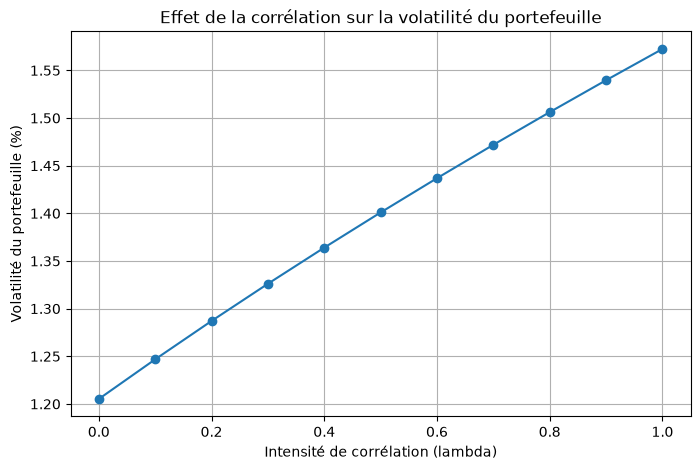

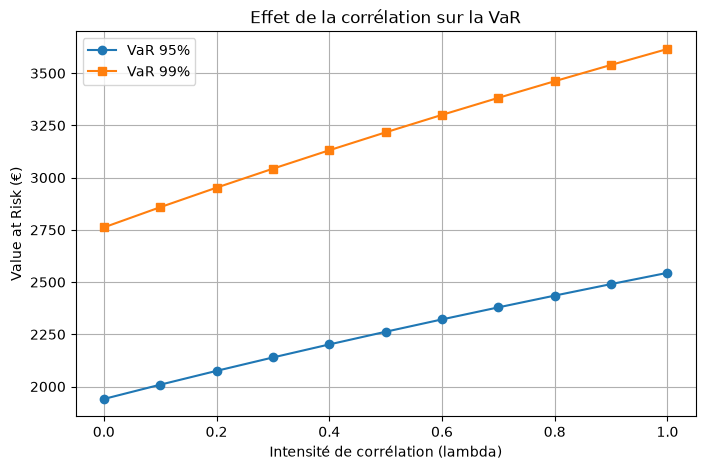

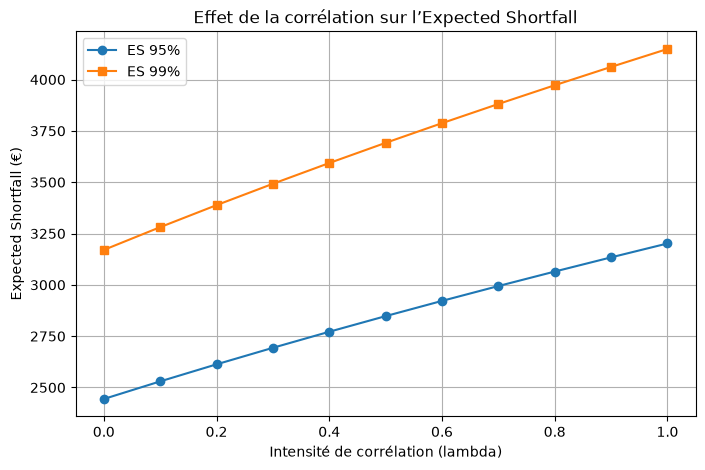

In [6]:
import matplotlib.pyplot as plt

# 1. Volatilité du portefeuille
plt.figure(figsize=(8, 5))

plt.plot(
    correlation_results["lambda"],
    correlation_results["portfolio_volatility"] * 100,
    marker="o"
)

plt.xlabel("Intensité de corrélation (lambda)")
plt.ylabel("Volatilité du portefeuille (%)")
plt.title("Effet de la corrélation sur la volatilité du portefeuille")
plt.grid(True)
plt.show()


# 2. Value at Risk
plt.figure(figsize=(8, 5))

plt.plot(
    correlation_results["lambda"],
    correlation_results["VaR_95"],
    marker="o",
    label="VaR 95%"
)

plt.plot(
    correlation_results["lambda"],
    correlation_results["VaR_99"],
    marker="s",
    label="VaR 99%"
)

plt.xlabel("Intensité de corrélation (lambda)")
plt.ylabel("Value at Risk (€)")
plt.title("Effet de la corrélation sur la VaR")
plt.legend()
plt.grid(True)
plt.show()


# 3. Expected Shortfall
plt.figure(figsize=(8, 5))

plt.plot(
    correlation_results["lambda"],
    correlation_results["ES_95"],
    marker="o",
    label="ES 95%"
)

plt.plot(
    correlation_results["lambda"],
    correlation_results["ES_99"],
    marker="s",
    label="ES 99%"
)

plt.xlabel("Intensité de corrélation (lambda)")
plt.ylabel("Expected Shortfall (€)")
plt.title("Effet de la corrélation sur l’Expected Shortfall")
plt.legend()
plt.grid(True)
plt.show()


In [7]:
from IPython.display import display, Markdown

# Premier et dernier scénarios de corrélation
independent = correlation_results.iloc[0]
original = correlation_results.iloc[-1]

# Calcul des augmentations relatives
vol_increase = (
    original["portfolio_volatility"]
    / independent["portfolio_volatility"] - 1
) * 100

var95_increase = (
    original["VaR_95"] / independent["VaR_95"] - 1
) * 100

es95_increase = (
    original["ES_95"] / independent["ES_95"] - 1
) * 100

var99_increase = (
    original["VaR_99"] / independent["VaR_99"] - 1
) * 100

es99_increase = (
    original["ES_99"] / independent["ES_99"] - 1
) * 100

display(Markdown(f"""
### Interprétation de l’effet de la corrélation

Quand les actifs sont indépendants (lambda = 0), la volatilité
du portefeuille est de **{independent['portfolio_volatility']*100:.3f} %**.

Avec la structure de corrélation d’origine (lambda = 1),
la volatilité du portefeuille passe à
**{original['portfolio_volatility']*100:.3f} %**.

Cela représente une hausse relative de
**{vol_increase:.2f} %**.

On observe la même tendance pour les mesures de risque :

| Mesure de risque | Actifs indépendants | Corrélations d’origine | Hausse |
|:--|--:|--:|--:|
| VaR 95 % | {independent['VaR_95']:,.2f} € | {original['VaR_95']:,.2f} € | {var95_increase:.2f} % |
| ES 95 % | {independent['ES_95']:,.2f} € | {original['ES_95']:,.2f} € | {es95_increase:.2f} % |
| VaR 99 % | {independent['VaR_99']:,.2f} € | {original['VaR_99']:,.2f} € | {var99_increase:.2f} % |
| ES 99 % | {independent['ES_99']:,.2f} € | {original['ES_99']:,.2f} € | {es99_increase:.2f} % |

Ces résultats illustrent l’importance de la corrélation
dans la gestion du risque d’un portefeuille. Quand les corrélations augmentent,
le bénéfice de diversification diminue, ce qui accroît
la volatilité, la VaR et l’Expected Shortfall du portefeuille.
"""))


### Interprétation de l’effet de la corrélation

Quand les actifs sont indépendants (lambda = 0), la volatilité
du portefeuille est de **1.205 %**.

Avec la structure de corrélation d’origine (lambda = 1),
la volatilité du portefeuille passe à
**1.572 %**.

Cela représente une hausse relative de
**30.47 %**.

On observe la même tendance pour les mesures de risque :

| Mesure de risque | Actifs indépendants | Corrélations d’origine | Hausse |
|:--|--:|--:|--:|
| VaR 95 % | 1,940.37 € | 2,544.40 € | 31.13 % |
| ES 95 % | 2,443.98 € | 3,201.45 € | 30.99 % |
| VaR 99 % | 2,761.71 € | 3,615.99 € | 30.93 % |
| ES 99 % | 3,170.11 € | 4,148.83 € | 30.87 % |

Ces résultats illustrent l’importance de la corrélation
dans la gestion du risque d’un portefeuille. Quand les corrélations augmentent,
le bénéfice de diversification diminue, ce qui accroît
la volatilité, la VaR et l’Expected Shortfall du portefeuille.


## 2.7. Interprétation financière et limites

Les résultats soulignent l’importance de la corrélation dans la gestion du risque d’un portefeuille.

Lorsque les rendements sont indépendants, la diversification réduit le risque global. À mesure que les corrélations augmentent, ce bénéfice diminue.

Dans cette expérience, le passage d’actifs indépendants à la structure de corrélation d’origine augmente d’environ 30 % la volatilité, la VaR et l’Expected Shortfall du portefeuille.

Ce résultat a une implication financière importante : un portefeuille qui semble bien diversifié en conditions normales peut devenir nettement plus risqué quand les corrélations augmentent.

Ce phénomène est particulièrement pertinent en période de stress financier, lorsque les corrélations entre actifs risqués peuvent augmenter simultanément. De telles situations peuvent amplifier les pertes et contribuer au risque systémique.

**Limites**

Cette expérience repose sur un modèle gaussien multivarié et modifie les corrélations en gardant les volatilités individuelles constantes.

Sur les marchés réels :

- les corrélations varient dans le temps et peuvent augmenter pendant les crises ;
- les rendements peuvent présenter des queues épaisses et une dépendance non linéaire ;
- les dynamiques de volatilité et de corrélation peuvent interagir ;
- une matrice de corrélation constante peut sous-estimer les pertes jointes extrêmes.

Une extension naturelle consisterait à utiliser des modèles de corrélation variable dans le temps, comme le DCC-GARCH (Dynamic Conditional Correlation), ou des modèles à copules pour capturer la dépendance non linéaire et la dépendance de queue.

# 3. Analyse de la convergence de Monte-Carlo

## 3.1. Objectif

Après avoir validé la cohérence théorique de nos modèles dans la Section 1 **Simulation de Monte-Carlo d’un portefeuille multi-actifs** sur une instance fixe, cette section approfondit l'étude du cadre gaussien en analysant la vitesse de convergence empirique de Monte-Carlo en fonction du nombre de simulations $N$.

Cette expérience étudie la convergence des estimateurs Monte-Carlo de la Value at Risk (VaR) et de l’Expected Shortfall (ES).

Les méthodes de Monte-Carlo estiment les mesures de risque en générant un grand nombre de scénarios aléatoires à partir d’une loi de probabilité donnée.

Ces estimations sont toutefois entachées d’une erreur d’échantillonnage, dont la précision s’améliore en général avec le nombre de scénarios simulés.

L’expérience examine la relation entre le nombre de simulations et la précision des mesures de risque estimées.

On utilise le modèle gaussien de portefeuille de la première expérience, avec les mêmes paramètres et les mêmes niveaux de confiance.

## 3.2. Cadre théorique

Soient $L_1, L_2, \ldots, L_N$ des pertes simulées indépendantes du portefeuille. Rappelons que $L_i \sim \mathcal{N}(\mu_L,\sigma_L^2)$  avec $\mu_L=-V_0\mu_p$ et $\sigma_L=V_0\sigma_p$. Notons que nous retravaillons avec la matrice de corrélation :
$$
\rho =
\begin{pmatrix}
1 & 0.6 & 0.3\\
0.6 & 1 & 0.4\\
0.3 & 0.4 & 1
\end{pmatrix}
$$

L’estimateur Monte-Carlo de la VaR au niveau de confiance $\alpha$ est le quantile empirique :

$$
\widehat{VaR}_{\alpha,N}
=
\inf\left\{
x :
\widehat{F}_N(x)\geq\alpha
\right\}
$$

où la fonction de répartition empirique est :

$$
\widehat{F}_N(x)
=
\frac{1}{N}
\sum_{i=1}^{N}
\mathbf{1}_{\{L_i\leq x\}}
$$

L’estimateur de l’Expected Shortfall s’obtient en moyennant les pertes qui dépassent la VaR estimée :

$$
\widehat{ES}_{\alpha,N}
=
\frac{
\sum_{i=1}^{N}
L_i\mathbf{1}_{\{L_i>\widehat{VaR}_{\alpha,N}\}}
}{
\sum_{i=1}^{N}
\mathbf{1}_{\{L_i>\widehat{VaR}_{\alpha,N}\}}
}
$$

Cet estimateur est intuitif, même si, à taille d’échantillon finie, ses valeurs peuvent différer légèrement de celles d’estimateurs fondés sur des quantiles empiriques fractionnaires.

## 3.3. Convergence de Monte-Carlo

Sous des conditions de régularité usuelles, l’erreur d’échantillonnage de Monte-Carlo décroît typiquement à une vitesse proportionnelle à :

$$
\frac{1}{\sqrt{N}}
$$

où $N$ est le nombre de scénarios simulés.

Multiplier le nombre de simulations par quatre divise donc l’erreur de Monte-Carlo par deux environ.

Cette relation est importante en pratique : améliorer la précision numérique devient coûteux, en particulier pour estimer des quantiles extrêmes et des mesures de risque de queue.

## 3.4. Méthodologie expérimentale

On considère plusieurs tailles de simulation, de quelques centaines de scénarios jusqu’à un grand nombre.

Pour chaque taille, on estime :

- la VaR au niveau de confiance de 95 % ;
- la VaR au niveau de confiance de 99 % ;
- l’ES au niveau de confiance de 95 % ;
- l’ES au niveau de confiance de 99 %.

On compare ensuite ces estimations à leurs équivalents gaussiens analytiques.

L’erreur relative d’estimation est définie par :

$$
\text{Erreur relative}
=
\frac{
|\text{Estimation Monte-Carlo} - \text{Valeur analytique}|
}{
|\text{Valeur analytique}|
}
\times 100
$$

Cela permet d’évaluer comment la précision des estimations évolue quand le nombre de simulations augmente.

## 3.5. Implémentations en Python

In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# Reproductibilité
rng = np.random.default_rng(42)

# Paramètres du portefeuille de l’expérience 1
V0 = 100_000

weights = np.array([0.5, 0.3, 0.2])

mu = np.array([0.0005, 0.0003, 0.0004])

sigma = np.array([0.02, 0.015, 0.025])

corr = np.array([
    [1.0, 0.6, 0.3],
    [0.6, 1.0, 0.4],
    [0.3, 0.4, 1.0]
])

# Matrice de covariance
D = np.diag(sigma)
cov = D @ corr @ D

# Paramètres analytiques des pertes du portefeuille
mu_p = weights @ mu
sigma_p = np.sqrt(weights @ cov @ weights)

mu_loss = -V0 * mu_p
sigma_loss = V0 * sigma_p

# Valeurs analytiques de référence
confidence_levels = [0.95, 0.99]

theoretical = {}

for alpha in confidence_levels:
    z = norm.ppf(alpha)

    theoretical[f"VaR_{int(alpha*100)}"] = (
        mu_loss + sigma_loss * z
    )

    theoretical[f"ES_{int(alpha*100)}"] = (
        mu_loss
        + sigma_loss * norm.pdf(z) / (1 - alpha)
    )

# Tailles de simulation
sample_sizes = [
    100, 500, 1_000, 5_000,
    10_000, 50_000, 100_000, 500_000
]

N_max = max(sample_sizes)

# Génération d’un grand échantillon Monte-Carlo unique
simulated_returns = rng.multivariate_normal(
    mean=mu,
    cov=cov,
    size=N_max
)

portfolio_returns = simulated_returns @ weights

losses = -V0 * portfolio_returns

# Estimation des mesures de risque pour des tailles croissantes
results = []

for N in sample_sizes:

    sample_losses = losses[:N]

    row = {"N": N}

    for alpha in confidence_levels:

        level = int(alpha * 100)

        var_est = np.quantile(
            sample_losses,
            alpha,
            method="linear"
        )

        tail_losses = sample_losses[
            sample_losses > var_est
        ]

        es_est = tail_losses.mean()

        row[f"VaR_{level}"] = var_est
        row[f"ES_{level}"] = es_est

        row[f"VaR_{level}_error"] = (
            abs(var_est - theoretical[f"VaR_{level}"])
            / abs(theoretical[f"VaR_{level}"])
            * 100
        )

        row[f"ES_{level}_error"] = (
            abs(es_est - theoretical[f"ES_{level}"])
            / abs(theoretical[f"ES_{level}"])
            * 100
        )

    results.append(row)

convergence_results = pd.DataFrame(results)

convergence_results


,N,VaR_95,ES_95,VaR_95_error,ES_95_error,VaR_99,ES_99,VaR_99_error,ES_99_error
0,100,2583.411563,3078.100748,1.533300,3.852853,3288.413812,3538.966588,9.059163,14.699693
1,500,2716.256538,3369.028475,6.754376,5.234527,3908.520435,4113.314182,8.089839,0.856097
2,1000,2611.037564,3272.487090,2.619058,2.218973,3908.456561,4176.691482,8.088072,0.671497
3,5000,2546.898046,3265.866942,0.098245,2.012187,3839.884243,4289.176645,6.191710,3.382746
4,10000,2575.912061,3261.370459,1.238554,1.871736,3712.316396,4191.628369,2.663831,1.031523
5,50000,2556.126276,3238.803547,0.460933,1.166839,3654.186984,4221.434465,1.056266,1.749945
6,100000,2544.357858,3214.564329,0.001590,0.409706,3637.035932,4188.135014,0.581955,0.947322
7,500000,2542.316222,3201.204974,0.081830,0.007585,3613.993754,4153.401965,0.055275,0.110146


## 3.6. Visualisation de la convergence de Monte-Carlo

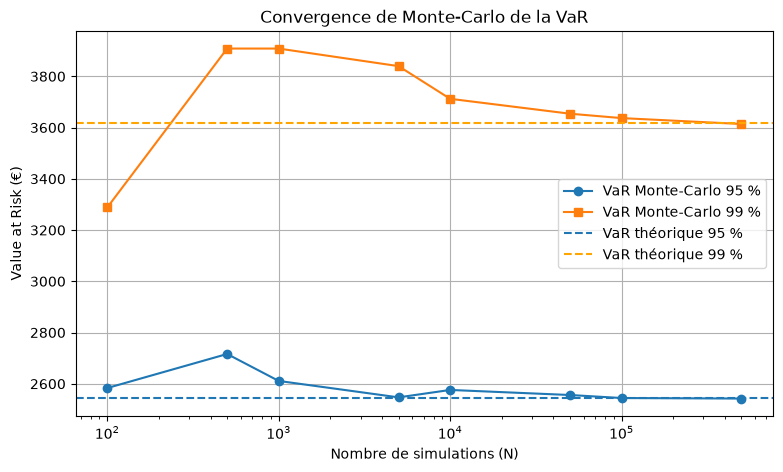

In [30]:

# Convergence de la VaR
plt.figure(figsize=(9, 5))

plt.plot(
    convergence_results["N"],
    convergence_results["VaR_95"],
    marker="o",
    label="VaR Monte-Carlo 95 %"
)

plt.plot(
    convergence_results["N"],
    convergence_results["VaR_99"],
    marker="s",
    label="VaR Monte-Carlo 99 %"
)

plt.axhline(
    theoretical["VaR_95"],
    linestyle="--",
    label="VaR théorique 95 %"
)

plt.axhline(
    theoretical["VaR_99"],
    linestyle="--",
    label="VaR théorique 99 %",
    color = 'orange'
)

plt.xscale("log")
plt.xlabel("Nombre de simulations (N)")
plt.ylabel("Value at Risk (€)")
plt.title("Convergence de Monte-Carlo de la VaR")
plt.legend()
plt.grid(True)
plt.show()


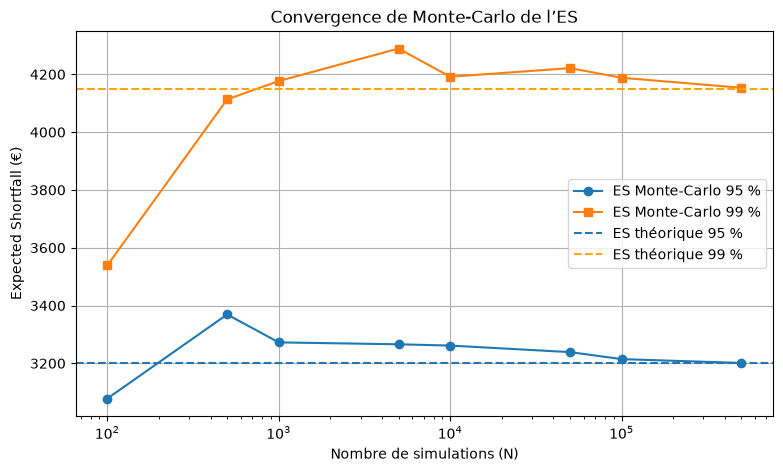

In [10]:

# Convergence de l’ES
plt.figure(figsize=(9, 5))

plt.plot(
    convergence_results["N"],
    convergence_results["ES_95"],
    marker="o",
    label="ES Monte-Carlo 95 %"
)

plt.plot(
    convergence_results["N"],
    convergence_results["ES_99"],
    marker="s",
    label="ES Monte-Carlo 99 %"
)

plt.axhline(
    theoretical["ES_95"],
    linestyle="--",
    label="ES théorique 95 %"
)

plt.axhline(
    theoretical["ES_99"],
    linestyle="--",
    label="ES théorique 99 %",
    color = 'orange'
)

plt.xscale("log")
plt.xlabel("Nombre de simulations (N)")
plt.ylabel("Expected Shortfall (€)")
plt.title("Convergence de Monte-Carlo de l’ES")
plt.legend()
plt.grid(True)
plt.show()


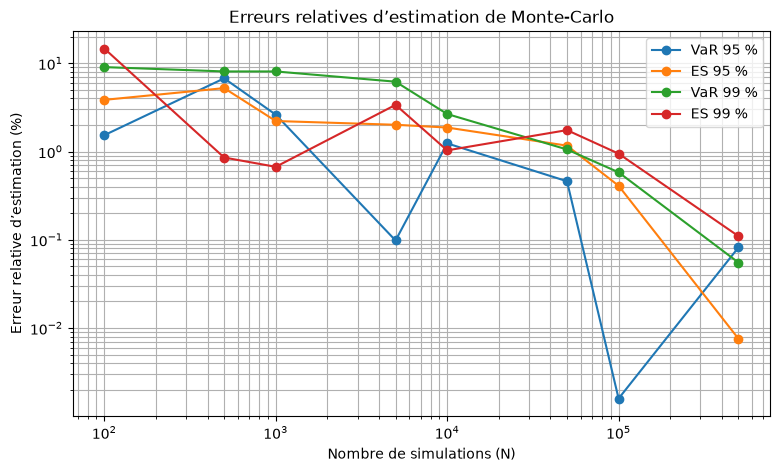

In [11]:

# Erreurs relatives d’estimation
plt.figure(figsize=(9, 5))

error_columns = [
    ("VaR_95_error", "VaR 95 %"),
    ("ES_95_error", "ES 95 %"),
    ("VaR_99_error", "VaR 99 %"),
    ("ES_99_error", "ES 99 %")
]

for column, label in error_columns:
    plt.plot(
        convergence_results["N"],
        convergence_results[column],
        marker="o",
        label=label
    )

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Nombre de simulations (N)")
plt.ylabel("Erreur relative d’estimation (%)")
plt.title("Erreurs relatives d’estimation de Monte-Carlo")
plt.legend()
plt.grid(True, which="both")
plt.show()


## 3.7. Interprétation automatique des résultats

In [12]:
from IPython.display import display, Markdown

first = convergence_results.iloc[0]
last = convergence_results.iloc[-1]

error_columns = [
    "VaR_95_error",
    "ES_95_error",
    "VaR_99_error",
    "ES_99_error"
]

max_final_error = last[error_columns].max()

display(Markdown(f"""
### Interprétation de la convergence de Monte-Carlo

Les résultats illustrent l’effet du nombre de simulations
sur la précision des estimations de risque par Monte-Carlo.

Avec **{int(first['N']):,} simulations**, les erreurs relatives
d’estimation sont :

- VaR 95 % : **{first['VaR_95_error']:.2f} %**
- ES 95 % : **{first['ES_95_error']:.2f} %**
- VaR 99 % : **{first['VaR_99_error']:.2f} %**
- ES 99 % : **{first['ES_99_error']:.2f} %**

Quand le nombre de simulations passe à
**{int(last['N']):,}**, les erreurs diminuent à :

- VaR 95 % : **{last['VaR_95_error']:.3f} %**
- ES 95 % : **{last['ES_95_error']:.3f} %**
- VaR 99 % : **{last['VaR_99_error']:.3f} %**
- ES 99 % : **{last['ES_99_error']:.3f} %**

L’erreur relative maximale pour la plus grande taille de
simulation est de **{max_final_error:.3f} %**.

Globalement, les estimations gagnent en précision quand
le nombre de simulations augmente. La convergence n’est toutefois
pas strictement monotone, car les estimations de Monte-Carlo
restent soumises aux fluctuations d’échantillonnage aléatoires.
"""))


### Interprétation de la convergence de Monte-Carlo

Les résultats illustrent l’effet du nombre de simulations
sur la précision des estimations de risque par Monte-Carlo.

Avec **100 simulations**, les erreurs relatives
d’estimation sont :

- VaR 95 % : **1.53 %**
- ES 95 % : **3.85 %**
- VaR 99 % : **9.06 %**
- ES 99 % : **14.70 %**

Quand le nombre de simulations passe à
**500,000**, les erreurs diminuent à :

- VaR 95 % : **0.082 %**
- ES 95 % : **0.008 %**
- VaR 99 % : **0.055 %**
- ES 99 % : **0.110 %**

L’erreur relative maximale pour la plus grande taille de
simulation est de **0.110 %**.

Globalement, les estimations gagnent en précision quand
le nombre de simulations augmente. La convergence n’est toutefois
pas strictement monotone, car les estimations de Monte-Carlo
restent soumises aux fluctuations d’échantillonnage aléatoires.


## 3.8. Interprétation financière et limites

L’expérience montre que la précision des estimations Monte-Carlo dépend fortement du nombre de scénarios simulés.

À mesure que la taille de la simulation augmente, la VaR et l’Expected Shortfall estimées se rapprochent en général de leurs valeurs gaussiennes analytiques.

Les résultats montrent aussi que les mesures de risque extrêmes sont plus difficiles à estimer avec précision. En particulier, la VaR et l’ES à 99 % reposent sur une fraction relativement faible des observations simulées, ce qui les rend plus sensibles à la variabilité d’échantillonnage.

Cela compte beaucoup en gestion quantitative des risques, où sous-estimer le risque de queue peut conduire à une allocation de capital insuffisante.

**Considérations de calcul**

La précision de Monte-Carlo s’améliore typiquement à une vitesse proportionnelle à $1/\sqrt{N}$. Gagner nettement en précision exige donc un effort de calcul considérablement plus grand.

**Limites**

Cette expérience utilise une seule séquence de scénarios simulés et évalue les estimations sur des préfixes de plus en plus longs. Les estimations pour différentes tailles d’échantillon sont donc dépendantes. (Le script `run_mc_convergence.py` répète l’expérience sur plusieurs tirages indépendants et moyenne l’erreur.)

De plus, le modèle gaussien fournit des valeurs de référence analytiques, ce qui permet de mesurer précisément les erreurs d’estimation. Dans les applications réelles, la vraie distribution des pertes est en général inconnue.

Des études complémentaires pourraient utiliser des simulations indépendantes répétées, des intervalles de confiance pour les estimateurs de risque, des techniques de réduction de variance ou des distributions à queues plus épaisses.

# 4. VaR historique et backtesting

## 4.1. Objectif

Cette expérience estime la Value at Risk par la méthode de simulation historique et évalue sa performance prédictive par backtesting statistique.

Contrairement aux approches gaussienne et Monte-Carlo, la VaR historique ne suppose aucune loi de probabilité explicite pour les rendements des actifs.

Elle s’appuie directement sur les observations passées du marché pour estimer la distribution des pertes potentielles.

La procédure de backtesting compare ensuite les niveaux de VaR prévus aux pertes réalisées du portefeuille, afin de juger si le modèle de risque produit des prévisions fiables.

## 4.2. Méthodologie de la VaR historique

Soit $L_1, L_2, \ldots, L_T$ un échantillon de pertes historiques du portefeuille (la loi de la perte $L_i$ au jour $i$ est inconnue).

La VaR historique au niveau de confiance $\alpha$ est le quantile empirique de la distribution des pertes observées :

$$
\widehat{VaR}_{\alpha}
=
\inf\left\{
x :
\widehat{F}_T(x)\geq\alpha
\right\}
$$

où la fonction de répartition empirique est :

$$
\widehat{F}_T(x)
=
\frac{1}{T}
\sum_{t=1}^{T}
\mathbf{1}_{\{L_t\leq x\}}
$$

Par exemple, au niveau de confiance de 99 %, la VaR historique correspond au 99ᵉ centile empirique des pertes historiques.

L’Expected Shortfall (ES) historique mesure la perte moyenne dans la proportion $(1-\alpha)$ des observations historiques les plus défavorables.

Elle est estimée par la moyenne des pertes historiques supérieures ou égales à la VaR empirique :

$$
\widehat{ES}_{\alpha}
=
\frac{
\sum_{t=1}^{T} L_t
\mathbf{1}_{\{L_t \geq \widehat{VaR}_{\alpha}\}}
}{
\sum_{t=1}^{T}
\mathbf{1}_{\{L_t \geq \widehat{VaR}_{\alpha}\}}
}
$$

Contrairement à la VaR, qui ne donne qu’un seuil de perte, l’ES renseigne aussi sur la sévérité des pertes au-delà de ce seuil.

La méthode est simple et n’exige aucune distribution paramétrique. Elle suppose cependant que les observations passées sont informatives sur le risque de marché futur.

## 4.3. VaR historique glissante

Pour évaluer la performance prédictive du modèle, on utilise une fenêtre glissante.

À chaque date $t$, la prévision de VaR n’utilise que les $W$ observations précédentes :

$$
\widehat{\operatorname{VaR}}_{t,\alpha}
=
Q_{\alpha}
\left(
L_{t-W},\ldots,L_{t-1}
\right)
$$

où :

- $W$ est la fenêtre d’estimation historique ;
- $Q_{\alpha}$ est le quantile empirique au niveau de confiance $\alpha$ ;
- $\widehat{\operatorname{VaR}}_{t,\alpha}$ est la prévision faite pour la date $t$.

La prévision d’Expected Shortfall correspondante est la moyenne des pertes historiques supérieures ou égales à la VaR estimée :

$$
\widehat{\operatorname{ES}}_{t,\alpha}
=
\frac{
\displaystyle\sum_{j=t-W}^{t-1}
L_j
\mathbf{1}_{\left\{L_j\geq\widehat{\operatorname{VaR}}_{t,\alpha}\right\}}
}{
\displaystyle\sum_{j=t-W}^{t-1}
\mathbf{1}_{\left\{L_j\geq\widehat{\operatorname{VaR}}_{t,\alpha}\right\}}
}
$$

Dans cette expérience, on utilise une fenêtre glissante fixe de 250 observations journalières. Chaque prévision de VaR et d’ES repose donc sur les 250 pertes les plus récentes disponibles avant la date de prévision.

La perte réalisée à la date $t$ est ensuite comparée à la prévision de VaR correspondante.

Cette approche glissante évite le biais d’anticipation : aucune information de la date $t$ ou des dates suivantes n’est utilisée pour construire les prévisions de la date $t$.

La procédure est répétée pour chaque date de la période hors échantillon, ce qui permet d’observer l’évolution des prévisions de risque dans le temps.

## 4.4. Dépassements de la VaR

Un dépassement de VaR survient lorsque la perte réalisée excède la VaR prévue :

$$
I_t =
\begin{cases}
1 & \text{si } L_t > \widehat{VaR}_{t,\alpha} \\
0 & \text{sinon}
\end{cases}
$$

Le nombre total de dépassements est :

$$
X = \sum_{t=1}^{T} I_t
$$

Pour un modèle de VaR correctement calibré, la probabilité de dépassement attendue est :

$$
p = 1-\alpha
$$

Par exemple :

- à 95 % de confiance, le taux de dépassement attendu est de 5 % ;
- à 99 % de confiance, il est de 1 %.

Un modèle qui produit trop de dépassements peut sous-estimer le risque. À l’inverse, un modèle qui en produit nettement moins peut être trop prudent.

## 4.5. Test de couverture inconditionnelle de Kupiec

Le test de Kupiec vérifie si la fréquence observée des dépassements est compatible avec la probabilité théorique $p=1-\alpha$.

Sous l’hypothèse nulle :

$$
H_0 : \mathbb{P}(I_t=1)=p
$$

Soient $T$ le nombre d’observations hors échantillon et $X$ le nombre de dépassements.

La fréquence observée de dépassements est :

$$
\widehat{p}=\frac{X}{T}
$$

La statistique du rapport de vraisemblance de Kupiec est :

$$
LR_{uc}
=
-2\ln
\left(
\frac{
(1-p)^{T-X}p^X
}{
(1-\widehat{p})^{T-X}
\widehat{p}^{X}
}
\right)
$$

Sous l’hypothèse nulle, la statistique suit asymptotiquement une loi du χ² à un degré de liberté :

$$
LR_{uc}\sim\chi^2(1)
$$

L’hypothèse nulle est rejetée au seuil de signification $\gamma$ si :

$$
LR_{uc}>\chi^2_{1,1-\gamma}
$$
où $\chi^2_{1,1-\gamma}$ désigne le quantile d'ordre $1-\gamma$ de la loi du Chi-deux à 1 degré de liberté.  

Le test évalue la fréquence des dépassements, mais pas leur indépendance dans le temps.

## 4.6. Test d’indépendance de Christoffersen

Le test de Christoffersen vérifie si les dépassements de VaR surviennent de façon indépendante dans le temps.

Un modèle de VaR bien calibré doit non seulement produire le nombre attendu de dépassements, mais aussi éviter leur regroupement.

On définit les effectifs de transitions :

- $n_{00}$ : transitions de « pas de dépassement » à « pas de dépassement » ;
- $n_{01}$ : transitions de « pas de dépassement » à « dépassement » ;
- $n_{10}$ : transitions de « dépassement » à « pas de dépassement » ;
- $n_{11}$ : transitions de « dépassement » à « dépassement ».

Les probabilités conditionnelles de dépassement sont estimées par :

$$
\widehat{\pi}_0 =
\frac{n_{01}}{n_{00}+n_{01}}
$$

$$
\widehat{\pi}_1 =
\frac{n_{11}}{n_{10}+n_{11}}
$$

Sous l’hypothèse d’indépendance, la probabilité d’un dépassement ne doit pas dépendre du résultat de la veille :

$$
H_0 : \pi_0 = \pi_1
$$

La statistique du rapport de vraisemblance est :

$$
LR_{ind}
=
-2\ln
\left(
\frac{
(1-\widehat{\pi})^{n_{00}+n_{10}}
\widehat{\pi}^{n_{01}+n_{11}}
}{
(1-\widehat{\pi}_0)^{n_{00}}
\widehat{\pi}_0^{n_{01}}
(1-\widehat{\pi}_1)^{n_{10}}
\widehat{\pi}_1^{n_{11}}
}
\right)
$$

où :

$$
\widehat{\pi}
=
\frac{n_{01}+n_{11}}
{n_{00}+n_{01}+n_{10}+n_{11}}
$$

Sous l’hypothèse nulle, la statistique suit asymptotiquement une loi du χ² à un degré de liberté.

## 4.7. Test de couverture conditionnelle

Le test de couverture conditionnelle combine les tests de Kupiec et de Christoffersen :

$$
LR_{cc}=LR_{uc}+LR_{ind}
$$

Sous l’hypothèse nulle conjointe, la statistique suit asymptotiquement une loi du χ² à deux degrés de liberté :

$$
LR_{cc}\sim\chi^2(2)
$$

Ce test évalue conjointement :

- si la fréquence des dépassements de VaR est correcte ;
- si les dépassements sont indépendants dans le temps.

Il donne ainsi une appréciation plus complète de la performance du modèle de VaR.

## 4.8. Méthodologie expérimentale

On implémente une VaR historique glissante avec une fenêtre d’estimation fixe.

La procédure est la suivante :

1. choisir une fenêtre d’estimation historique ;
2. calculer la VaR empirique à partir des observations passées ;
3. comparer la prévision à la perte réalisée à la date suivante ;
4. répéter la procédure sur toute la période hors échantillon ;
5. compter les dépassements de VaR ;
6. appliquer les tests de Kupiec, de Christoffersen et de couverture conditionnelle.

L’analyse est menée aux niveaux de confiance de 95 % et de 99 %.

## 4.9. Données historiques et rendements du portefeuille

In [13]:
import pandas as pd
import numpy as np

from var_es.data import download_prices
from var_es.portfolio import make_weights, portfolio_returns

# Données de marché historiques (mêmes ETF et mêmes dates que scripts/run_backtest.py)
weights = make_weights({"SPY": 0.50, "QQQ": 0.30, "IWM": 0.20})
tickers = list(weights.index)

start_date = "2010-01-01"
end_date = "2026-11-01"

prices = download_prices(
    tickers=tickers,
    start=start_date,
    end=end_date,
    cache_dir="../data"
)

# Rendements journaliers des actifs
asset_returns = prices.pct_change().dropna()

# Rendements journaliers du portefeuille (poids alignés par nom de ticker)
returns = portfolio_returns(
    returns=asset_returns,
    weights=weights
)

# Conversion des rendements en pertes monétaires
V0 = 100_000

portfolio_losses = -V0 * returns

# Affichage des résultats
display(prices.head())
display(returns.head())
display(portfolio_losses.describe())


,SPY,QQQ,IWM
Date,,,
2010-01-04,84.368973,40.204662,51.111202
2010-01-05,84.592308,40.204662,50.935459
2010-01-06,84.651840,39.962158,50.887527
2010-01-07,85.009209,39.988129,51.262997
2010-01-08,85.292107,40.317268,51.542603


Date
2010-01-05    0.000636
2010-01-06   -0.001646
2010-01-07    0.003781
2010-01-08    0.005224
2010-01-11   -0.001332
Name: portfolio, dtype: float64

count     4232.000000
mean       -61.472765
std       1158.503941
min     -10551.931606
25%       -643.631605
50%        -84.483708
75%        427.041969
max      11718.215203
Name: portfolio, dtype: float64

Le jeu de données historiques contient les prix journaliers ajustés de trois ETF cotés aux États-Unis : SPY (S&P 500), QQQ (Nasdaq-100) et IWM (Russell 2000), de janvier 2010 à fin octobre 2026. Ce sont les mêmes ETF, poids et dates que dans `scripts/run_backtest.py` et le README : tous les chiffres de ce notebook sont donc reproductibles en ligne de commande.

Les prix ajustés tiennent compte des opérations sur titres comme les dividendes, ce qui les rend adaptés au calcul de rendements d’investissement. Les rendements simples journaliers se calculent à partir de prix ajustés consécutifs :

$$
r_{i,t}=\frac{P_{i,t}}{P_{i,t-1}}-1
$$

où $P_{i,t}$ désigne le prix ajusté de l’actif $i$ à la date $t$.

On considère un portefeuille à poids constants (SPY 50 %, QQQ 30 %, IWM 20 %), indexés par ticker, de sorte que l’alignement ne dépende jamais de l’ordre des colonnes. Le rendement du portefeuille est $r_{p,t}=\sum_i w_i r_{i,t}$ et la perte est $L_t=-r_{p,t}$.

In [14]:
import pandas as pd
import numpy as np

from var_es.portfolio import make_weights, portfolio_returns

# Poids indexés par ticker (somme vérifiée égale à 1)
weights = make_weights({"SPY": 0.50, "QQQ": 0.30, "IWM": 0.20})

# Rendements journaliers des actifs
asset_returns = prices.pct_change().dropna()

# Rendements journaliers du portefeuille
returns = portfolio_returns(asset_returns, weights)

# Valeur initiale du portefeuille
V0 = 100_000

# Pertes en fraction de la valeur du portefeuille
portfolio_losses = -returns

# Affichage des résultats
display(asset_returns.head())
display(returns.head().to_frame())
display(portfolio_losses.head().to_frame())


,SPY,QQQ,IWM
Date,,,
2010-01-05,0.002647,0.000000,-0.003438
2010-01-06,0.000704,-0.006032,-0.000941
2010-01-07,0.004222,0.000650,0.007378
2010-01-08,0.003328,0.008231,0.005454
2010-01-11,0.001397,-0.004082,-0.004030


,portfolio
Date,
2010-01-05,0.000636
2010-01-06,-0.001646
2010-01-07,0.003781
2010-01-08,0.005224
2010-01-11,-0.001332


,portfolio
Date,
2010-01-05,-0.000636
2010-01-06,0.001646
2010-01-07,-0.003781
2010-01-08,-0.005224
2010-01-11,0.001332


In [15]:
print("Nombre d’observations de prix :", len(prices))
print("Nombre d’observations de rendements du portefeuille :", len(returns))
print("Première date de rendement :", returns.index.min())
print("Dernière date de rendement :", returns.index.max())
print("Rendements manquants :", returns.isna().sum())

print("\nPoids du portefeuille :")
display(weights)

print("\nStatistiques des rendements du portefeuille :")
display(returns.describe())

Nombre d’observations de prix : 4233
Nombre d’observations de rendements du portefeuille : 4232
Première date de rendement : 2010-01-05 00:00:00
Dernière date de rendement : 2026-10-30 00:00:00
Rendements manquants : 0

Poids du portefeuille :


SPY    0.5
QQQ    0.3
IWM    0.2
dtype: float64


Statistiques des rendements du portefeuille :


count    4232.000000
mean        0.000615
std         0.011585
min        -0.117182
25%        -0.004270
50%         0.000845
75%         0.006436
max         0.105519
Name: portfolio, dtype: float64

## 4.10 VaR et ES historiques glissantes

On calcule maintenant la Value at Risk (VaR) et l’Expected Shortfall (ES) historiques glissantes aux niveaux de confiance de 95 % et 99 %.

Les mesures de risque sont estimées sur une fenêtre glissante de 250 rendements journaliers passés du portefeuille. À chaque date, l’estimation n’utilise que des observations disponibles avant cette date : aucune information future n’entre dans les prévisions.

Les estimations de VaR et d’ES sont exprimées en fraction de la valeur du portefeuille. On les convertit aussi en montants monétaires à partir de la valeur initiale $V_0 = 100\,000$ EUR pour faciliter l’interprétation.

In [16]:
from var_es.backtest import rolling_var_es, violations

window = 250
alphas = [0.95, 0.99]

forecasts = {}
violation_series = {}

for alpha in alphas:
    forecasts[alpha] = rolling_var_es(
        returns=returns,
        alpha=alpha,
        method="historical",
        window=window,
        start=window
    )

    violation_series[alpha] = violations(
        returns=returns,
        var_series=forecasts[alpha]["var"]
    )

# Conversion des prévisions de VaR et d’ES en euros
forecasts_eur = {
    alpha: forecasts[alpha] * V0
    for alpha in alphas
}

In [17]:
for alpha in alphas:
    print(f"\nNiveau de confiance : {alpha:.0%}")
    print("Nombre de prévisions :", len(forecasts[alpha]))
    print("Première date de prévision :", forecasts[alpha].index.min())
    print("Dernière date de prévision :", forecasts[alpha].index.max())
    print("Nombre de dépassements de VaR :", violation_series[alpha].sum())

    display(forecasts_eur[alpha].describe())


Niveau de confiance : 95%
Nombre de prévisions : 3982
Première date de prévision : 2010-12-31 00:00:00
Dernière date de prévision : 2026-10-30 00:00:00
Nombre de dépassements de VaR : 210


,var,es
count,3982.000000,3982.000000
mean,1763.913530,2560.375901
std,590.738015,983.098984
min,579.261046,1136.541015
25%,1358.701568,1820.795317
50%,1634.233788,2296.052512
75%,2075.092411,2936.214982
max,3231.191537,5572.240541



Niveau de confiance : 99%
Nombre de prévisions : 3982
Première date de prévision : 2010-12-31 00:00:00
Dernière date de prévision : 2026-10-30 00:00:00
Nombre de dépassements de VaR : 66


,var,es
count,3982.000000,3982.000000
mean,3061.667508,3728.470719
std,1265.181684,1854.686778
min,1545.386009,1884.567650
25%,2144.771831,2475.173496
50%,2682.197536,3364.399760
75%,3665.496289,4208.693522
max,6934.227793,9798.703706


## 4.11 Visualisation des prévisions de VaR et des pertes réalisées

On compare les pertes journalières réalisées du portefeuille aux prévisions de VaR historique glissante.

Un dépassement de VaR survient chaque fois que la perte réalisée excède la VaR prévue. Ces observations sont mises en évidence sur le graphique, pour juger visuellement à quelle fréquence et dans quelles conditions de marché le modèle sous-estime les pertes.

L’analyse est menée aux niveaux de confiance de 95 % et de 99 %.

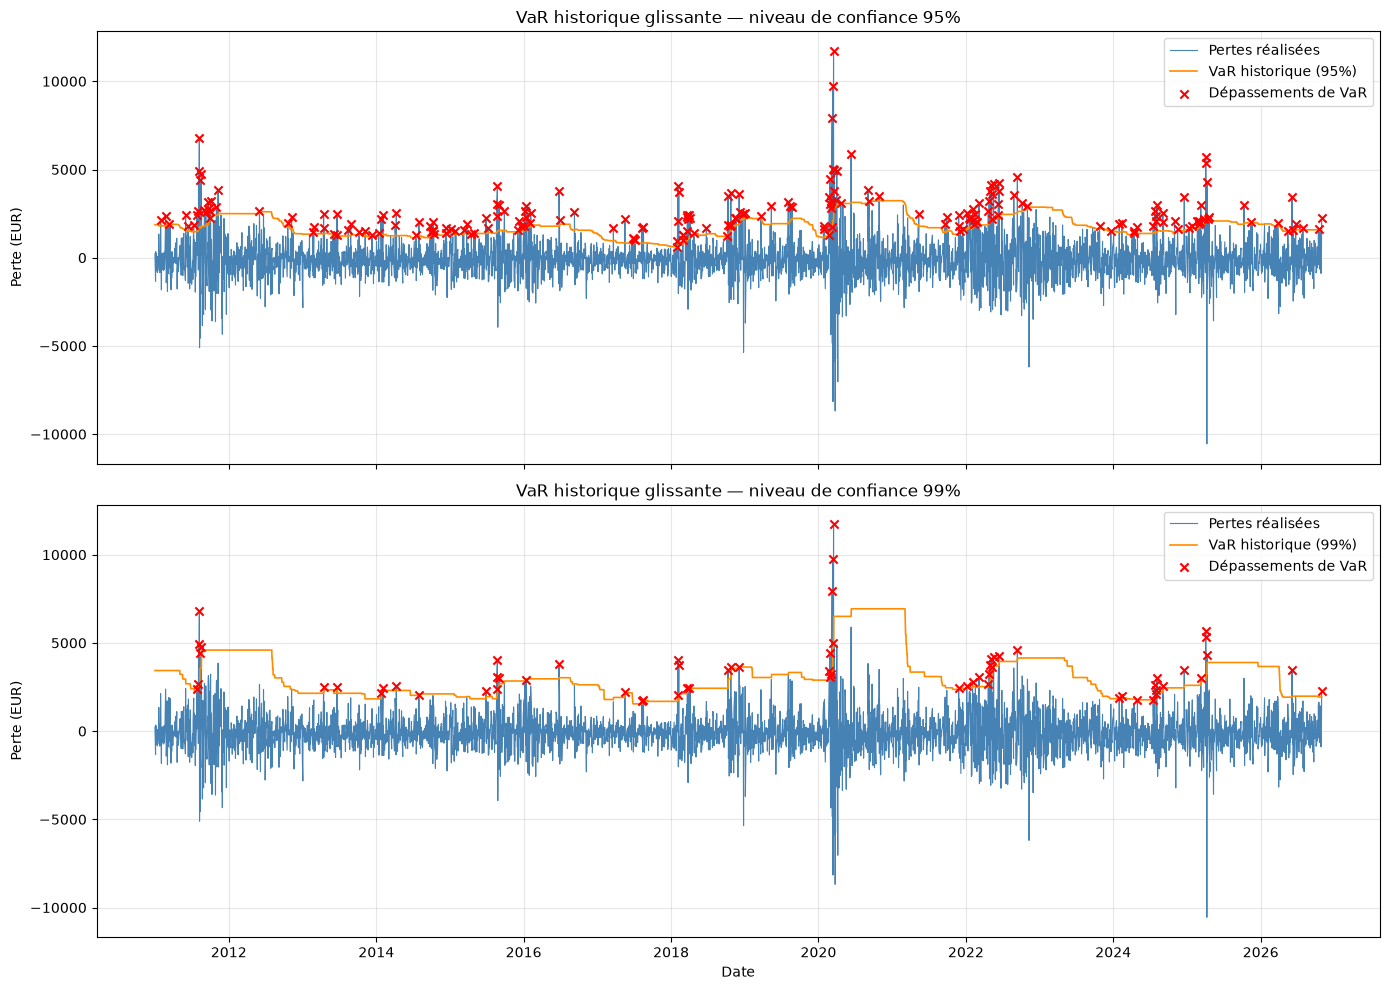

In [18]:
import matplotlib.pyplot as plt

realized_losses = -returns.loc[forecasts[0.99].index] * V0

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

for ax, alpha in zip(axes, alphas):
    label = f"{alpha:.0%}"
    var_eur = forecasts_eur[alpha]["var"]
    violations_alpha = violation_series[alpha]

    ax.plot(
        realized_losses.index,
        realized_losses,
        color="steelblue",
        linewidth=0.8,
        label="Pertes réalisées"
    )

    ax.plot(
        var_eur.index,
        var_eur,
        color="darkorange",
        linewidth=1.2,
        label=f"VaR historique ({label})"
    )

    ax.scatter(
        realized_losses.index[violations_alpha],
        realized_losses.loc[violations_alpha.index[violations_alpha]],
        color="red",
        marker="x",
        s=35,
        label="Dépassements de VaR",
        zorder=3
    )

    ax.set_title(f"VaR historique glissante — niveau de confiance {label}")
    ax.set_ylabel("Perte (EUR)")
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

In [19]:
for alpha in alphas:
    n_obs = len(violation_series[alpha])
    n_viol = int(violation_series[alpha].sum())
    expected = n_obs * (1 - alpha)

    print(f"\nNiveau de confiance : {alpha:.0%}")
    print(f"Nombre d’observations : {n_obs}")
    print(f"Dépassements observés : {n_viol}")
    print(f"Dépassements attendus : {expected:.1f}")
    print(f"Taux de dépassement observé : {n_viol / n_obs:.2%}")


Niveau de confiance : 95%
Nombre d’observations : 3982
Dépassements observés : 210
Dépassements attendus : 199.1
Taux de dépassement observé : 5.27%

Niveau de confiance : 99%
Nombre d’observations : 3982
Dépassements observés : 66
Dépassements attendus : 39.8
Taux de dépassement observé : 1.66%


## 4.12 Synthèse du backtesting

On compare d’abord le nombre de dépassements de VaR observé au nombre attendu pour un modèle correctement calibré.

Sous l’hypothèse nulle de couverture inconditionnelle correcte, la probabilité de dépassement doit valoir $1-\alpha$. Le nombre attendu de dépassements est donc :

$$
\mathbb{E}[N_{\text{dépassements}}]
=
n(1-\alpha),
$$

où $n$ désigne le nombre d’observations hors échantillon. Ou encore $\mathbb{E}[X]= T(1-\alpha)$ pour reprendre les notations des sections **4.4** et **4.5**.

La comparaison des fréquences de dépassement observée et attendue donne une première appréciation de la calibration de la VaR. Des tests statistiques formels permettent ensuite de juger si les écarts sont significatifs.

In [20]:
from var_es.backtest import backtest_summary

summary_rows = []

for alpha in alphas:
    result = backtest_summary(violation_series[alpha], alpha)
    result["niveau_confiance"] = f"{alpha:.0%}"
    summary_rows.append(result)

summary_df = (
    pd.DataFrame(summary_rows)
    .set_index("niveau_confiance")
)

display(
    summary_df[
        [
            "n_obs",
            "violations",
            "attendues",
            "taux",
            "LR_kupiec",
            "p_kupiec",
            "LR_ind",
            "p_ind",
            "LR_cc",
            "p_cc"
        ]
    ].round(4)
)

,n_obs,violations,attendues,taux,LR_kupiec,p_kupiec,LR_ind,p_ind,LR_cc,p_cc
niveau_confiance,,,,,,,,,,
95%,3982,210,199.1,0.0527,0.6176,0.4320,21.3153,0.0,21.9329,0.0
99%,3982,66,39.8,0.0166,14.5119,0.0001,19.7868,0.0,34.2987,0.0


## 4.13 Interprétation des résultats du backtesting

La VaR historique glissante (fenêtre de 250 jours) est évaluée sur 3 982 jours hors échantillon.

Toutes les p-valeurs ($p_{\text{kupiec}}$, $p_{\text{ind}}$, $p_{\text{cc}}$) sont comparées au seuil de signification standard $\gamma = 5\%$ ($0{,}05$). Une p-valeur supérieure à $0{,}05$ valide l'hypothèse nulle $H_0$ (modèle adéquat), tandis qu'une p-valeur inférieure à $0{,}05$ conduit au rejet de $H_0$ (défaillance du modèle).

Au niveau de confiance de 95 %, le taux de dépassement observé (5,27 %) est proche des 5 % théoriques, et le test de Kupiec ne rejette pas la couverture inconditionnelle ($p_{\text{kupiec}}=0{,}43$). En revanche, le test d’indépendance de Christoffersen rejette nettement ($p_{\text{ind}}<0{,}001$) : les dépassements arrivent par paquets, typiquement en périodes agitées. Le test de couverture conditionnelle rejette donc le modèle.

Au niveau de confiance de 99 %, le taux de dépassement est de 1,66 %, bien au-dessus du 1 % théorique. Kupiec rejette la couverture inconditionnelle ($p_{\text{kupiec}}\approx 10^{-4}$), le test d’indépendance rejette aussi, de même que la couverture conditionnelle.

Dans l’ensemble, une fenêtre historique statique retrouve à peu près la fréquence *moyenne* correcte à 95 %, mais ne s’adapte pas à l’évolution de la volatilité et sous-estime les pertes extrêmes à 99 %. Cela motive les modèles à volatilité dynamique de la section 5.

## 4.14 Conclusion

Cette section a évalué un modèle de VaR historique glissante sur un portefeuille de trois ETF (SPY, QQQ, IWM), avec une fenêtre de 250 jours aux niveaux de 95 % et 99 %, sur 3 982 observations hors échantillon.

À 95 %, la fréquence de dépassements est acceptable, mais les dépassements sont regroupés dans le temps (indépendance rejetée). À 99 %, la fréquence comme l’indépendance des dépassements sont rejetées.

Cela illustre l’importance de backtester les mesures de risque au lieu de se fier à leur seule définition, ainsi qu’une limite essentielle de la simulation historique : avec des poids égaux sur toute la fenêtre, l’estimation réagit lentement aux régimes de volatilité et ne représente pas les événements extrêmes absents de la fenêtre.

# 5. EWMA et simulation historique filtrée

## 5.1 Introduction et objectifs

Le modèle de VaR historique de la section précédente repose sur une fenêtre glissante de rendements passés. Il donne cependant la même importance à toutes les observations de la fenêtre et ne tient pas explicitement compte des variations de la volatilité du marché.

Sur les marchés financiers, la volatilité varie dans le temps et présente souvent un regroupement : les périodes de forte volatilité tendent à être suivies de périodes de forte volatilité, et les périodes calmes à durer.

Cette section introduit deux approches qui prennent en compte cette dynamique :

- **Moyenne mobile exponentielle (EWMA) :** estime la volatilité conditionnelle en donnant davantage de poids aux observations récentes.
- **Simulation historique filtrée (FHS) :** combine un modèle de volatilité et la simulation historique. Les rendements sont d’abord standardisés par leur volatilité conditionnelle estimée, puis les rendements standardisés historiques servent à estimer la distribution des pertes futures.

L’objectif est d’examiner si l’introduction d’une volatilité variable dans le temps améliore l’estimation de la VaR et de l’Expected Shortfall, en particulier quand les conditions de marché changent.

## 5.2 Modèle de volatilité EWMA

Le modèle de moyenne mobile exponentielle (EWMA) sert à estimer la volatilité financière variable dans le temps. Contrairement à un estimateur de volatilité historique classique, qui pondère également les observations passées, l’EWMA donne plus d’importance aux rendements récents.

La variance conditionnelle est mise à jour récursivement par :

$$
\sigma_t^2
=
\lambda \sigma_{t-1}^2
+
(1-\lambda)r_{t-1}^2
$$

où :

- $\sigma_t^2$ est la variance conditionnelle estimée à la date $t$ ;
- $r_{t-1}$ est le rendement du portefeuille observé à la date $t-1$ ;
- $\sigma_{t-1}^2$ est l’estimation précédente de la variance conditionnelle ;
- $\lambda$ est le facteur de décroissance, avec $0<\lambda<1$.

Dans cette étude, on utilise le paramètre conventionnel de RiskMetrics :

$$
\lambda = 0.94
$$

Une valeur élevée de $\lambda$ donne plus de persistance aux estimations passées de la volatilité, tandis qu’une valeur plus faible donne plus de poids aux mouvements récents du marché.

Le modèle EWMA capte le regroupement de volatilité : la variance estimée augmente après de fortes variations du marché et décroît progressivement pendant les périodes calmes.

La variance initiale est estimée par la variance empirique des 30 premiers rendements journaliers du portefeuille. Les estimations suivantes se déduisent récursivement.

Pour éviter le biais d’anticipation, l’estimation de variance utilisée pour évaluer le risque à la date $t$ n’intègre que les rendements observés jusqu’à la date $t-1$.

La volatilité conditionnelle correspondante est :

$$
\sigma_t = \sqrt{\sigma_t^2}
$$

Cette estimation de volatilité variable dans le temps sert, dans la section suivante, à construire des mesures de risque ajustées de la volatilité et à mettre en œuvre la simulation historique filtrée.

## 5.3 Estimation de la volatilité EWMA

On met maintenant en œuvre le modèle EWMA à partir des rendements journaliers du portefeuille calculés en section 4.

La variance conditionnelle initiale est estimée à partir des 30 premiers rendements journaliers. Les estimations suivantes sont calculées récursivement avec la formule EWMA et $\lambda=0.94$.

L’implémentation suit une convention « un pas en avant » : l’estimation de volatilité associée à la date $t$ n’utilise que les rendements observés jusqu’à la date $t-1$. Les 30 premières observations ne servent donc qu’à l’initialisation ; l’implémentation se trouve dans `var_es/ewma.py`.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from var_es.ewma import ewma_volatility as compute_ewma_vol, ewma_var_es

# Paramètres EWMA (les mêmes que dans scripts/run_backtest.py)
lambda_ewma = 0.94
warmup = 30        # première variance = variance des 30 premiers rendements
first_forecast = 500

# Volatilité conditionnelle un pas en avant (n’utilise que les rendements jusqu’en t-1)
ewma_volatility = compute_ewma_vol(returns, lam=lambda_ewma, warmup=warmup)
ewma_volatility.name = "ewma_volatility"


In [22]:
print("Paramètre EWMA :", lambda_ewma)
print("Nombre d’observations :", len(ewma_volatility))
print("Estimations de volatilité disponibles :", ewma_volatility.notna().sum())
print("Première date de volatilité :", ewma_volatility.first_valid_index())
print("Dernière date de volatilité :", ewma_volatility.last_valid_index())

display(ewma_volatility.describe())

Paramètre EWMA : 0.94
Nombre d’observations : 4202
Estimations de volatilité disponibles : 4202
Première date de volatilité : 2010-02-18 00:00:00
Dernière date de volatilité : 2026-10-30 00:00:00


count    4202.000000
mean        0.010346
std         0.005266
min         0.003615
25%         0.007222
50%         0.008914
75%         0.011982
max         0.050978
Name: ewma_volatility, dtype: float64

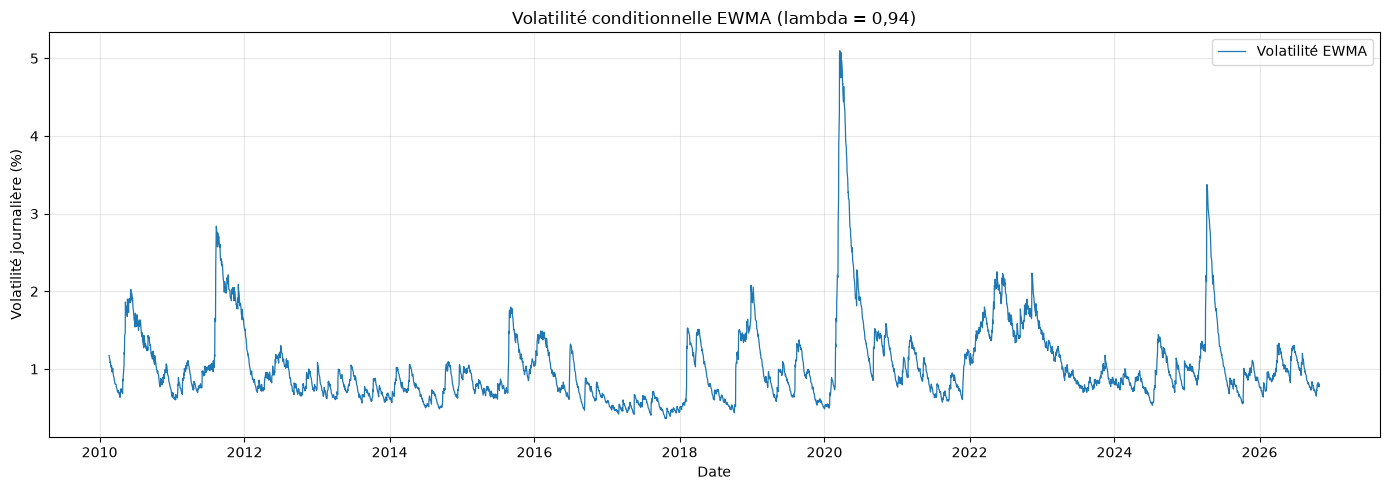

In [23]:
plt.figure(figsize=(14, 5))

plt.plot(
    ewma_volatility.index,
    ewma_volatility * 100,
    label="Volatilité EWMA",
    linewidth=0.9
)

plt.title("Volatilité conditionnelle EWMA (lambda = 0,94)")
plt.xlabel("Date")
plt.ylabel("Volatilité journalière (%)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 5.4 Simulation historique filtrée (FHS)

*Remarque sur le périmètre de prévision :*
Le jeu de données initial compte 4 232 rendements quotidiens. L'initialisation du modèle EWMA sur les 30 premiers jours laisse 4 202 estimations de volatilité conditionnelle. Enfin, l'exigence d'une fenêtre glissante d'amorçage de $W = 250$ jours sur les rendements standardisés $z_t$ pour évaluer le premier quantile empirique fixe la première date de prévision au 28/12/2011, soit un total de 3 732 prévisions hors-échantillon (contre 3 982 pour la VaR historique statique).

La simulation historique filtrée (FHS) combine un modèle de volatilité conditionnelle et la simulation historique.

L’idée centrale est de séparer la composante de volatilité variable dans le temps de la distribution des rendements standardisés.

On standardise d’abord les rendements journaliers du portefeuille par la volatilité conditionnelle EWMA :

$$
z_t = \frac{r_t}{\sigma_t}
$$

où $r_t$ est le rendement du portefeuille et $\sigma_t$ l’estimation de volatilité EWMA.

Les rendements standardisés servent ensuite à construire une distribution empirique de chocs historiques. À chaque date, cette distribution est remise à l’échelle par la volatilité conditionnelle courante pour obtenir des prévisions de risque du portefeuille.

En utilisant l’ensemble croissant de tous les rendements standardisés passés, la VaR FHS est estimée par :

$$
\operatorname{VaR}_{t,\alpha}^{\text{FHS}} = -\sigma_t Q_{1-\alpha}\left(\mathcal{Z}_{t-1}\right)
$$

où le symbole $\mathcal{Z}_{t-1} = \{z_1, z_2, \ldots, z_{t-1}\}$ désigne l'ensemble de l'échantillon historique des rendements standardisés passés disponibles jusqu'à la date $t-1$ et $Q_{1-\alpha}\left(\mathcal{Z}_{t-1}\right)$ désigne le quantile empirique des rendements standardisés d'ordre $1-\alpha$. On notera $Q_{1-\alpha}\left(z_{t}\right) = Q_{1-\alpha}\left(\mathcal{Z}_{t-1}\right)$.

L’Expected Shortfall correspondante est :

$$
\operatorname{ES}_{t,\alpha}^{FHS}
=
-\sigma_t
\mathbb{E}
\left[
z_t \mid z_t \leq Q_{1-\alpha}(z_t)
\right]
$$

Cette approche conserve la distribution empirique des chocs historiques tout en adaptant les estimations de risque à la volatilité courante du marché.

Pour éviter le biais d’anticipation, seuls les rendements standardisés observés avant la date $t$ servent à estimer les mesures de risque de cette date.

In [24]:
fhs_forecasts = {}
fhs_violations = {}

for alpha in alphas:
    fhs_forecasts[alpha] = ewma_var_es(
        returns, alpha, lam=lambda_ewma, method="fhs", start=first_forecast
    )
    fhs_violations[alpha] = violations(
        returns=returns,
        var_series=fhs_forecasts[alpha]["var"]
    )

# Conversion des prévisions en euros
fhs_forecasts_eur = {
    alpha: fhs_forecasts[alpha] * V0
    for alpha in alphas
}


In [25]:
for alpha in alphas:
    print(f"\nNiveau de confiance : {alpha:.0%}")
    print("Nombre de prévisions :", len(fhs_forecasts[alpha]))
    print("Première date de prévision :", fhs_forecasts[alpha].index.min())
    print("Dernière date de prévision :", fhs_forecasts[alpha].index.max())
    print("Nombre de dépassements :", int(fhs_violations[alpha].sum()))

    display(fhs_forecasts_eur[alpha].describe().round(2))


Niveau de confiance : 95%
Nombre de prévisions : 3732
Première date de prévision : 2011-12-28 00:00:00
Dernière date de prévision : 2026-10-30 00:00:00
Nombre de dépassements : 181


,var,es
count,3732.00,3732.00
mean,1761.61,2569.72
std,892.67,1370.15
min,625.02,916.64
25%,1260.65,1782.64
50%,1532.88,2217.34
75%,2033.45,2967.86
max,8807.61,13508.40



Niveau de confiance : 99%
Nombre de prévisions : 3732
Première date de prévision : 2011-12-28 00:00:00
Dernière date de prévision : 2026-10-30 00:00:00
Nombre de dépassements : 39


,var,es
count,3732.00,3732.00
mean,3068.62,3868.19
std,1654.59,2145.93
min,1094.44,1392.16
25%,2107.32,2583.68
50%,2649.94,3327.51
75%,3556.88,4504.44
max,16294.92,20932.12


## 5.5 Backtesting du modèle FHS

On évalue maintenant le modèle FHS avec le même cadre de backtesting statistique qu’en section 4.

Le nombre observé de dépassements de VaR est comparé au nombre théorique attendu sous une couverture inconditionnelle correcte.

Le test de Kupiec évalue la couverture inconditionnelle, tandis que les tests de Christoffersen examinent l’indépendance des dépassements et la couverture conditionnelle.

Afin de garantir une comparaison stricte et équitable entre les modèles, la VaR historique statique est réévaluée sur la même période hors-échantillon que la FHS (3 732 prévisions du 28/12/2011 au 30/10/2026), en excluant les 250 premiers jours d'amorçage.

Le seuil de signification est fixé à 5 %.

In [26]:
from var_es.backtest import backtest_summary

fhs_summary_rows = []

for alpha in alphas:
    result = backtest_summary(fhs_violations[alpha], alpha)
    result["niveau_confiance"] = f"{alpha:.0%}"
    fhs_summary_rows.append(result)

fhs_summary_df = (
    pd.DataFrame(fhs_summary_rows)
    .set_index("niveau_confiance")
)

display(fhs_summary_df.round(4))

,n_obs,violations,attendues,taux,LR_kupiec,p_kupiec,LR_ind,p_ind,LR_cc,p_cc
niveau_confiance,,,,,,,,,,
95%,3732,181,186.6,0.0485,0.1786,0.6726,1.2220,0.2690,1.4006,0.4964
99%,3732,39,37.3,0.0105,0.0753,0.7838,11.7782,0.0006,11.8535,0.0027


In [27]:
comparison_rows = []

for alpha in alphas:

    common_index = fhs_forecasts[alpha].index

    historical_violations_common = (
        violation_series[alpha].loc[common_index]
    )

    fhs_violations_common = fhs_violations[alpha]

    for method, violation_data in [
        ("Historique", historical_violations_common),
        ("FHS", fhs_violations_common)
    ]:
        n_obs = len(violation_data)
        n_viol = int(violation_data.sum())

        comparison_rows.append({
            "niveau_confiance": f"{alpha:.0%}",
            "méthode": method,
            "observations": n_obs,
            "violations": n_viol,
            "violations_attendues": n_obs * (1 - alpha),
            "taux_dépassement": n_viol / n_obs
        })

fhs_comparison_df = pd.DataFrame(comparison_rows)

display(
    fhs_comparison_df
    .set_index(["niveau_confiance", "méthode"])
    .round(4)
)

observations  violations  violations_attendues  \
niveau_confiance méthode                                                      
95%              Historique          3732         189                186.60   
                 FHS                 3732         181                186.60   
99%              Historique          3732          60                 37.32   
                 FHS                 3732          39                 37.32   

                             taux_dépassement  
niveau_confiance méthode                       
95%              Historique            0.0506  
                 FHS                   0.0485  
99%              Historique            0.0161  
                 FHS                   0.0105

## 5.6 Interprétation et comparaison des résultats

Les deux modèles sont comparés sur les mêmes 3 732 jours (première prévision après 500 observations).

Au niveau de 95 %, la FHS produit 181 dépassements (4,85 %) contre 189 (5,06 %) pour le modèle historique sur 250 jours : les deux sont proches des 5 % théoriques. La différence tient à la *chronologie* : le modèle FHS ne rejette pas l’indépendance ($p=0{,}27$), alors que le modèle historique la rejette nettement ($p<0{,}001$). La FHS passe les trois tests à 95 %.

Au niveau de 99 %, la FHS produit 39 dépassements (1,05 %) contre 60 (1,61 %) pour le modèle historique, proche des 37,3 attendus. Kupiec ne rejette pas la FHS ($p=0{,}78$), mais les dépassements restent regroupés ($p\approx 0{,}0006$) : la couverture conditionnelle reste donc rejetée ($p\approx 0{,}003$).

Globalement, l’introduction de la volatilité EWMA corrige la *fréquence* des dépassements à 99 % et leur *regroupement* à 95 %, mais pas leur regroupement à 99 %.

Ces résultats sont à lire avec prudence : ils dépendent de $\lambda$, d’un seul portefeuille de trois ETF très corrélés, et du nombre de modèles comparés sur les mêmes données (pas de correction pour les tests multiples). À 99 %, seuls une quarantaine de dépassements sont attendus. Pour compléter cette analyse et isoler l'effet propre de la volatilité conditionnelle par rapport au choix de la loi de distribution, nous comparons à présent ces deux approches aux quatre autres configurations standards dans la section suivante.

## 5.7 Comparaison complète des six modèles

Les sections 4 et 5 ont construit pas à pas deux modèles : la VaR historique glissante et l’EWMA + FHS. Pour situer ces résultats, on compare ici **six modèles** sur exactement les mêmes dates, en appelant la fonction `compare_models` du package `var_es` (la même que `scripts/run_backtest.py`, d’où des chiffres identiques à ceux du README) :

- gaussienne en fenêtre croissante et en fenêtre glissante de 250 jours ;
- historique en fenêtre croissante et en fenêtre glissante de 250 jours ;
- EWMA gaussienne ($\lambda=0.94$) ;
- EWMA + FHS ($\lambda=0.94$).

Les « fenêtres croissantes » utilisent tout le passé disponible à chaque date ; les « fenêtres glissantes » seulement les 250 derniers jours.

In [28]:
from var_es.comparison import compare_models

comparison_table, _, _ = compare_models(
    returns,
    alphas=(0.95, 0.99),
    first_forecast=first_forecast,
    window=250,
    lam=lambda_ewma,
)

display(
    comparison_table[["alpha", "modèle", "n_obs", "violations", "attendues",
                      "taux", "p_kupiec", "p_ind", "p_cc"]].round(4)
)

,alpha,modèle,n_obs,violations,attendues,taux,p_kupiec,p_ind,p_cc
0,0.95,gaussienne (croissante),3732,165,186.6,0.0442,0.0982,0.0000,0.0000
1,0.95,gaussienne (glissante 250),3732,199,186.6,0.0533,0.3566,0.0000,0.0001
2,0.95,historique (croissante),3732,175,186.6,0.0469,0.3788,0.0001,0.0002
3,0.95,historique (glissante 250),3732,189,186.6,0.0506,0.8572,0.0000,0.0000
4,0.95,EWMA gaussienne (λ=0.94),3732,213,186.6,0.0571,0.0523,0.3927,0.1055
5,0.95,EWMA + FHS (λ=0.94),3732,181,186.6,0.0485,0.6726,0.2690,0.4964
6,0.99,gaussienne (croissante),3732,74,37.3,0.0198,0.0000,0.0001,0.0000
7,0.99,gaussienne (glissante 250),3732,88,37.3,0.0236,0.0000,0.0002,0.0000
8,0.99,historique (croissante),3732,41,37.3,0.0110,0.5512,0.0009,0.0034
9,0.99,historique (glissante 250),3732,60,37.3,0.0161,0.0006,0.0000,0.0000


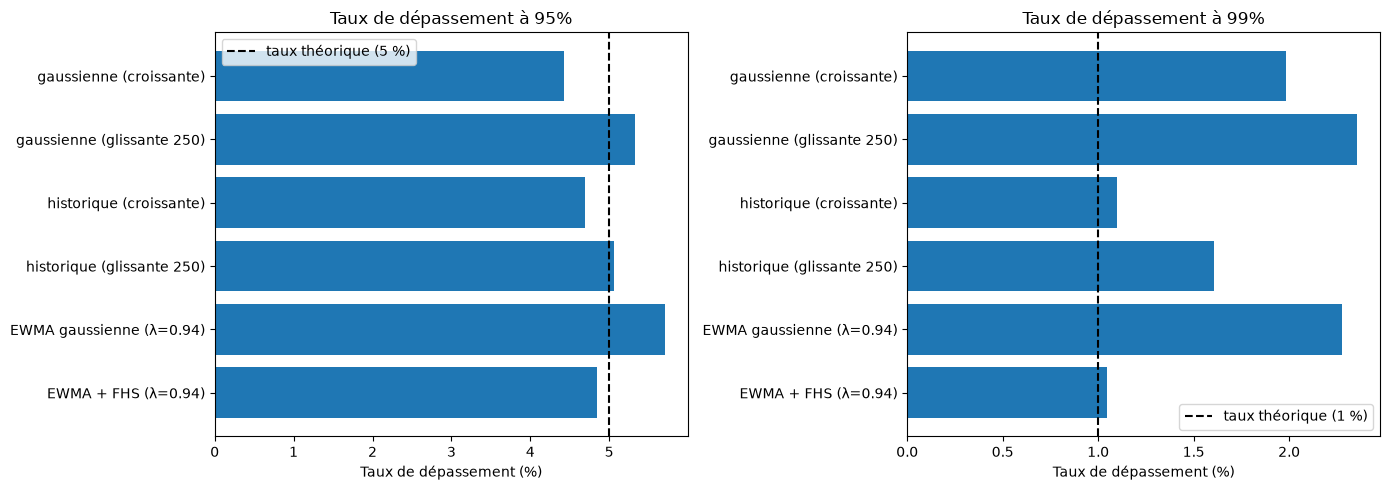

In [29]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

for ax, alpha in zip(axes, (0.95, 0.99)):
    sub = comparison_table[comparison_table["alpha"] == alpha].iloc[::-1]
    ax.barh(sub["modèle"], 100 * sub["taux"])
    ax.axvline(100 * (1 - alpha), color="black", linestyle="--",
               label=f"taux théorique ({100 * (1 - alpha):.0f} %)")
    ax.set_title(f"Taux de dépassement à {alpha:.0%}")
    ax.set_xlabel("Taux de dépassement (%)")
    ax.legend()

plt.tight_layout()
plt.show()

### Lecture des résultats

- **À 95 %**, tous les modèles ont un taux de dépassement proche de 5 %. Ce qui les distingue est l’*indépendance* : les modèles à volatilité constante (gaussienne, historique) rejettent nettement l’indépendance ($p<0{,}001$), tandis que les deux modèles EWMA ne la rejettent pas. Les deux EWMA passent les trois tests ; la FHS le fait plus confortablement (Kupiec $p=0{,}67$ contre $0{,}052$ pour l’EWMA gaussienne, à la limite du rejet).
- **À 99 %**, les VaR gaussiennes produisent environ **deux fois trop de dépassements** (74 à 88 pour 37,3 attendus), même avec une volatilité EWMA : la loi normale sous-estime les queues. L’historique en fenêtre croissante et la FHS retrouvent la fréquence attendue.
- **Aucun modèle ne passe les trois tests à 99 %** : même la FHS conserve des dépassements regroupés (indépendance rejetée, $p\approx 0{,}0006$).

Ces conclusions restent soumises aux réserves de la section 5.6 : un seul portefeuille de trois ETF corrélés, pas de correction pour les comparaisons multiples, peu de dépassements à 99 %.

## 5.8 Conclusion

Cette section a introduit la modélisation de la volatilité conditionnelle par **EWMA ($\lambda=0{,}94$)** et la **Simulation Historique Filtrée (FHS)** pour pallier les faiblesses structurales de la VaR historique statique.

L'évaluation comparative de l'ensemble des approches apporte trois constats fondamentaux :

1. **Suppression du *volatility clustering*** : L'ajustement dynamique de la variance conditionnelle via l'EWMA permet d'adapter la VaR dès le lendemain d'un choc de marché. La FHS passe ainsi avec succès l'intégralité des tests de couverture et d'indépendance au niveau 95 % ($p_{\text{cc}} = 0{,}496$).
2. **Correction des queues épaisses à 99 %** : Là où l'EWMA gaussienne échoue au niveau 99 % en raison d'une sous-estimation des pertes extrêmes ($p_{\text{kupiec}} < 0{,}001$), le filtrage empirique de la FHS ramène le taux de dépassement à $1{,}05\%$ (pour $1\%$ théorique).
3. **Limites subsistantes** : Bien que la FHS surpasse nettement les autres modèles, les dépassements extrêmement violents à 99 % conservent une légère dépendance temporelle ($p_{\text{ind}} \approx 0{,}0006$). La performance du modèle reste sensible au choix du facteur de décroissance $\lambda$ et à la profondeur de la fenêtre d'amorçage.

En résolvant le problème de retard d'adaptation tout en conservant la distribution réelle des chocs de marché, la Simulation Historique Filtrée s'impose comme la méthodologie la plus robuste et la plus complète développée dans ce projet.

# 6. Discussion, limites et conclusion

Cette dernière section propose une évaluation d’ensemble des méthodes d’estimation du risque implémentées dans le projet. Elle compare leurs principales caractéristiques et leurs performances au backtesting, discute les limites du cadre de modélisation et identifie des pistes d’amélioration.

L’objectif est d’évaluer non seulement les résultats numériques obtenus, mais aussi les hypothèses sous-jacentes de chaque approche et leurs implications pour la gestion pratique du risque de marché.

---

## 6.1 Comparaison des méthodes d’estimation du risque

Ce projet explore trois approches fondamentales de l’estimation du risque de marché : l’approche paramétrique gaussienne, la simulation historique et la simulation historique filtrée (FHS).

* **Approche gaussienne** :
  Elle suppose que les rendements du portefeuille suivent une loi normale, permettant le calcul analytique de la VaR et de l'ES à partir de la moyenne et de l'écart-type. Son principal avantage réside dans sa simplicité de calcul. L’hypothèse de normalité sous-estime toutefois la probabilité de pertes extrêmes lorsque les rendements présentent des queues épaisses ou une volatilité variable.

* **Simulation historique** :
  Elle estime la VaR et l’ES directement à partir de la distribution empirique des pertes passées, sans hypothèse paramétrique sur la loi des rendements. Elle conserve ainsi la non-normalité observée. En revanche, elle suppose que le passé récent reste représentatif du futur proche et accuse un temps de retard d'adaptation lors des régimes de crise.

* **Simulation historique filtrée (FHS)** :
  Elle allie la souplesse de la simulation historique à la dynamique temporelle d'un modèle EWMA ($\lambda = 0{,}94$) pour rééchelonner les chocs empiriques $z_t = r_t / \sigma_t$. Cette approche s’adapte rapidement aux changements de volatilité tout en préservant l'épaisseur réelle des queues de distribution.

**Comparaison d’ensemble :**
Les trois approches illustrent différents arbitrages entre hypothèses théoriques, simplicité de calcul et réactivité temporelle. La comparaison par backtesting (présentée en **section 5.7**) démontre que modéliser la volatilité conditionnelle améliore drastiquement la précision de la VaR. À 99 %, les modèles gaussiens produisent environ deux fois plus de dépassements que prévu (74 à 88 pour 37,3 attendus), tandis que la FHS et la simulation historique ajustée restent proches de la fréquence théorique.

---

## 6.2 Limites et pistes d’amélioration

Bien que les modèles implémentés offrent un cadre robuste, plusieurs limites théoriques et pratiques doivent être soulignées :

1. **Dépendance aux données historiques** :
   La simulation historique et la FHS s’appuient sur des observations passées qui peuvent ne pas capturer des régimes de crise inédits. Une amélioration consisterait à compléter le modèle par des scénarios de *stress testing* ou de l'analyse de scénarios extrêmes hors-échantillon.

2. **Sensibilité à la fenêtre glissante ($W = 250$ jours)** :
   Le choix de 250 jours constitue un compromis classique (1 an de cotation). Une fenêtre plus courte augmenterait la réactivité au prix d'une instabilité des quantiles ; une fenêtre plus longue stabiliserait l'estimation mais conserverait des chocs périmés.

3. **Spécification du paramètre $\lambda$ de l'EWMA** :
   Le paramètre $\lambda = 0{,}94$ (standard RiskMetrics) est appliqué de manière fixe. Une optimisation statistique du paramètre ou le passage à un modèle **GARCH(1,1)** permettrait d'intégrer un phénomène de retour à la moyenne (*mean-reversion*) de la variance.

4. **Puissance statistique du backtesting à 99 %** :
   À des seuils de confiance très élevés, le faible nombre de dépassements attendus (~37 sur 3 732 jours) limite la puissance statistique des tests du $\chi^2$ (Kupiec et Christoffersen) pour détecter des défauts d'ajustement subtils.

5. **Absence de backtesting sur l'Expected Shortfall (ES)** :
   Seule la VaR a fait l'objet d'un backtesting statistique. L'ES étant une mesure sous-additive mais non-élicitable au sens strict, son évaluation statistique nécessiterait l'implémentation de tests d'élicitabilité conjointe VaR/ES, comme la méthodologie d'**Acerbi–Székely (2014)** adoptée par Bâle III / FRTB.

6. **Hypothèse sur la moyenne des rendements** :
   La VaR gaussienne glissante prend en compte la moyenne empirique des pertes, tandis que l’EWMA fixe la moyenne conditionnelle à zero. Bien que l'écart reste négligeable à l'échelle journalière, il constitue une légère divergence méthodologique.

---

## 6.3 Conclusion générale

Ce projet a permis de développer un moteur complet de calcul et de validation statistique du risque de marché (*var-es-risk-engine*) sur un portefeuille réinvesti d'ETF (`SPY` 50 %, `QQQ` 30 %, `IWM` 20 %) couvrant plus de 16 années de cotation.

L’intégration d’estimations de volatilité dynamique (EWMA) associée au filtrage des chocs empiriques (FHS) s'impose comme la méthodologie la plus performante. En ramenant le nombre de dépassements à 99 % à 39 (pour 37,3 théoriques) et en éliminant le *clustering* de volatilité au niveau 95 % ($p_{\text{cc}} = 0{,}496$), la FHS résout l'essentiel des faiblesses des modèles statiques et gaussiens.

Au-delà des métriques numériques, ce travail illustre l'importance d'allier dérivation mathématique rigoureuse, programmation Python modulaire et évaluation statistique systématique. Il démontre que la fiabilité des mesures de risque financières dépend moins de leur complexité théorique que de la pertinence de leurs hypothèses de volatilité et de distribution face aux réalités du marché.